In [92]:
"""
STEP 5: LoLiMoT - LOCAL LINEAR MODEL TREE
==========================================

Implementation of LoLiMoT (Local Linear Model Tree) for prediction of velocity fields
- Information sharing between local models via validity functions.

Implementation of LoLiMoT with multiple model types for comparison:
- LNU: Linear (Ridge regression)
- QNU: Quadratic (Polynomial features + Ridge)
- MLP: Neural Network (MLPRegressor)

Approach:
- Manually defined REGIONS based on flow physics (x and z partitioning)
- Train ONE LOCAL LINEAR MODEL per region
- Use VALIDITY FUNCTIONS (Gaussian) to blend predictions
- Smooth transitions between regions

Regions are defined based on flow physics:
- X-direction: Upstream, Cube, Near Wake, Far Wake
- Z-direction: Near-wall, Cube height, Mixing layer, Outer flow

Author: Vit Uhlir
"""

from setup_paths import PROCESSED_DATA_DIR, RESULTS_DIR, FIGURES_DIR, REPORTS_DIR
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import warnings
warnings.filterwarnings('ignore')

In [93]:
# ============================================================================
# CONFIGURATION
# ============================================================================

# INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data.pkl'
# INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data_11.pkl'
# INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data_21.pkl'
INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data_25_uniform.pkl'
# INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data_51.pkl'

OUTPUT_DIR = FIGURES_DIR
RESULTS_OUTPUT = REPORTS_DIR / 'step5_lolimot_results.pkl'


# Cube geometry
H_CUBE = 0.015  # meters
X_CUBE_FRONT = 0.075  # meters (x/H = 5.0)
X_CUBE_BACK = 0.090   # meters (x/H = 6.0)

# Random state for reproducibility
RANDOM_STATE = 42

# Plot settings
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 10

In [94]:
# ============================================================================
# MODEL CONFIGURATION
# ============================================================================

# MODEL_TYPE options: 'LNU', 'QNU', 'MLP', 'ALL'
# 'ALL' trains all three and compares them
MODEL_TYPE = 'ALL'

# Model-specific settings
RIDGE_ALPHA = 0.1          # Regularization for LNU and QNU
QNU_DEGREE = 2             # Polynomial degree for QNU
MLP_HIDDEN_LAYERS = (20, 10)  # Hidden layer sizes for MLP
MLP_MAX_ITER = 2000        # Max iterations for MLP
MLP_ALPHA = 0.001          # Regularization for MLP

# Plot settings
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 10

print("="*80)
print(" "*15 + "STEP 3C: LoLiMoT (ENHANCED WITH LNU/QNU/MLP)")
print("="*80)
print(f"\nModel type: {MODEL_TYPE}")
if MODEL_TYPE == 'ALL':
    print("  → Training LNU, QNU, and MLP for comparison")


               STEP 3C: LoLiMoT (ENHANCED WITH LNU/QNU/MLP)

Model type: ALL
  → Training LNU, QNU, and MLP for comparison


In [95]:
# ============================================================================
# REGION DEFINITION (PHYSICS-BASED)
# ============================================================================

print(f"\n{'='*80}")
print("DEFINING PHYSICS-BASED REGIONS")
print("="*80)

# X-direction regions (in meters)
X_REGIONS = {
    'upstream':    {'min': 0.000, 'max': 0.065, 'center': 0.030, 'sigma': 0.025},
    'cube':        {'min': 0.065, 'max': 0.095, 'center': 0.080, 'sigma': 0.015},
    'near_wake':   {'min': 0.090, 'max': 0.150, 'center': 0.115, 'sigma': 0.030},
    'far_wake':    {'min': 0.135, 'max': 0.320, 'center': 0.200, 'sigma': 0.060},
}

# Z-direction regions (in meters)
Z_REGIONS = {
    'near_wall':   {'min': 0.0000, 'max': 0.0075, 'center': 0.00375, 'sigma': 0.004},
    'cube_height': {'min': 0.0060, 'max': 0.0180, 'center': 0.01200, 'sigma': 0.005},
    'mixing':      {'min': 0.0150, 'max': 0.0300, 'center': 0.02250, 'sigma': 0.006},
    'outer':       {'min': 0.0250, 'max': 0.0500, 'center': 0.03750, 'sigma': 0.010},
}

# Create all region combinations
REGIONS = {}
region_id = 0
for x_name, x_params in X_REGIONS.items():
    for z_name, z_params in Z_REGIONS.items():
        region_key = f"{x_name}_{z_name}"
        REGIONS[region_key] = {
            'id': region_id,
            'x_name': x_name,
            'z_name': z_name,
            'x_center': x_params['center'],
            'z_center': z_params['center'],
            'x_sigma': x_params['sigma'],
            'z_sigma': z_params['sigma'],
            'x_min': x_params['min'],
            'x_max': x_params['max'],
            'z_min': z_params['min'],
            'z_max': z_params['max'],
        }
        region_id += 1

N_REGIONS = len(REGIONS)
print(f"\n✓ Created {N_REGIONS} regions ({len(X_REGIONS)} x-regions × {len(Z_REGIONS)} z-regions)")

print(f"\nX-direction regions:")
for name, params in X_REGIONS.items():
    print(f"  {name:12s}: x/H = [{params['min']/H_CUBE:.1f}, {params['max']/H_CUBE:.1f}], "
          f"center = {params['center']/H_CUBE:.1f}, σ = {params['sigma']/H_CUBE:.2f}")

print(f"\nZ-direction regions:")
for name, params in Z_REGIONS.items():
    print(f"  {name:12s}: z/H = [{params['min']/H_CUBE:.1f}, {params['max']/H_CUBE:.1f}], "
          f"center = {params['center']/H_CUBE:.2f}, σ = {params['sigma']/H_CUBE:.2f}")



DEFINING PHYSICS-BASED REGIONS

✓ Created 16 regions (4 x-regions × 4 z-regions)

X-direction regions:
  upstream    : x/H = [0.0, 4.3], center = 2.0, σ = 1.67
  cube        : x/H = [4.3, 6.3], center = 5.3, σ = 1.00
  near_wake   : x/H = [6.0, 10.0], center = 7.7, σ = 2.00
  far_wake    : x/H = [9.0, 21.3], center = 13.3, σ = 4.00

Z-direction regions:
  near_wall   : z/H = [0.0, 0.5], center = 0.25, σ = 0.27
  cube_height : z/H = [0.4, 1.2], center = 0.80, σ = 0.33
  mixing      : z/H = [1.0, 2.0], center = 1.50, σ = 0.40
  outer       : z/H = [1.7, 3.3], center = 2.50, σ = 0.67


In [96]:
# ============================================================================
# VALIDITY FUNCTION
# ============================================================================

def validity_function(x, z, region):
    """Gaussian validity function for a region."""
    x_c = region['x_center']
    z_c = region['z_center']
    sigma_x = region['x_sigma']
    sigma_z = region['z_sigma']
    
    phi = np.exp(-((x - x_c)**2 / (2 * sigma_x**2) + 
                   (z - z_c)**2 / (2 * sigma_z**2)))
    return phi


def compute_all_validities(x, z, regions):
    """Compute normalized validity weights for all regions."""
    validities = {}
    total = 0.0
    
    for region_key, region in regions.items():
        phi = validity_function(x, z, region)
        validities[region_key] = phi
        total += phi
    
    if total > 0:
        for key in validities:
            validities[key] /= total
    
    return validities

print(f"\n✓ Validity function defined")



✓ Validity function defined


In [97]:
# ============================================================================
# LOAD DATA
# ============================================================================

print(f"\n{'='*80}")
print("LOADING DATA")
print("="*80)

with open(INPUT_FILE, 'rb') as f:
    all_cases_data = pickle.load(f)

print(f"✓ Loaded {len(all_cases_data)} cases")

# Extract case parameters
case_parameters = {}
for case_id, case_data in all_cases_data.items():
    case_parameters[case_id] = {
        'U_ref': case_data['U_ref'],
        'profile_type': case_data['profile_type'],
        'profile_name': case_data['profile_name'],
    }



LOADING DATA
✓ Loaded 8 cases


In [98]:
# ============================================================================
# ONE-HOT ENCODING
# ============================================================================

print(f"\n{'='*80}")
print("ONE-HOT ENCODING")
print("="*80)

profile_types_all = np.array([[cp['profile_type']] for cp in case_parameters.values()])
onehot_encoder = OneHotEncoder(sparse_output=False, categories='auto')
onehot_encoder.fit(profile_types_all)

PROFILE_TYPE_MAP = {0: 'Uniform', 1: 'ABL+constant', 2: 'ABL+free', 3: 'ABL+laminar'}
N_PROFILE_TYPES = 4

print(f"✓ Profile type encoder fitted")

# Feature names
FEATURE_NAMES = ['x_norm', 'z_norm', 'U_ref', 'type_Uniform', 'type_ABL+const', 'type_ABL+free', 'type_ABL+lam']
N_FEATURES = len(FEATURE_NAMES)

print(f"✓ Features: {FEATURE_NAMES}")


ONE-HOT ENCODING
✓ Profile type encoder fitted
✓ Features: ['x_norm', 'z_norm', 'U_ref', 'type_Uniform', 'type_ABL+const', 'type_ABL+free', 'type_ABL+lam']


In [99]:
# ============================================================================
# AUTOMATIC TRAIN/TEST SPLIT (Proportional by Flow Regime)
# ============================================================================

print(f"\n{'='*80}")
print("TRAIN/TEST SPLIT BY FLOW REGIME")
print("="*80)

all_x_locations = sorted(list(set([x for case_data in all_cases_data.values() 
                                     for x in case_data['profiles'].keys()])))

print(f"\nAvailable x-locations: {len(all_x_locations)}")
print(f"  x/H: {[f'{x/H_CUBE:.1f}' for x in all_x_locations]}")

# Categorize by flow regime
X_RECOVERY = 0.14

regime_locations = {
    'upstream': [],
    'over_cube': [],
    'wake': [],
    'far_downstream': []
}

for x in all_x_locations:
    if x < X_CUBE_FRONT:
        regime_locations['upstream'].append(x)
    elif x <= X_CUBE_BACK:
        regime_locations['over_cube'].append(x)
    elif x < X_RECOVERY:
        regime_locations['wake'].append(x)
    else:
        regime_locations['far_downstream'].append(x)

print(f"\n📍 Locations by flow regime:")
for regime, locs in regime_locations.items():
    x_H = [f'{x/H_CUBE:.1f}' for x in locs]
    print(f"  {regime:15s}: {len(locs):2d} locations  (x/H: {x_H})")


# TEST SELECTION STRATEGY
# Option 1: Fixed 1 per regime (current)
# Option 2: Proportional (~20% from each regime)
# Option 3: Fixed total percentage

TEST_STRATEGY = 'proportional'  # Options: 'one_per_regime', 'proportional', 'percentage'
TEST_FRACTION = 0.2  # For 'proportional' and 'percentage' strategies

x_test = []
test_selection = {}

if TEST_STRATEGY == 'one_per_regime':
    # Original: 1 test location per regime (always 4 total)
    for regime, locs in regime_locations.items():
        if len(locs) >= 2:
            mid_idx = len(locs) // 2
            x_test.append(locs[mid_idx])
            test_selection[regime] = [locs[mid_idx]]
        elif len(locs) == 1:
            test_selection[regime] = []
            print(f"  ⚠️  {regime}: Only 1 location, keeping for training")
        else:
            test_selection[regime] = []

elif TEST_STRATEGY == 'proportional':
    # Proportional: ~20% from each regime, minimum 1 if regime has ≥3 points
    for regime, locs in regime_locations.items():
        n_locs = len(locs)
        if n_locs >= 3:
            # Take ~20% but at least 1
            n_test = max(1, int(n_locs * TEST_FRACTION))
            # Select evenly spaced indices (not edges)
            if n_test == 1:
                indices = [n_locs // 2]
            else:
                # Avoid first and last, distribute evenly
                indices = np.linspace(1, n_locs - 2, n_test, dtype=int)
            selected = [locs[i] for i in indices]
            x_test.extend(selected)
            test_selection[regime] = selected
        elif n_locs == 2:
            # Take middle-ish (index 1)
            x_test.append(locs[1])
            test_selection[regime] = [locs[1]]
        elif n_locs == 1:
            test_selection[regime] = []
            print(f"  ⚠️  {regime}: Only 1 location, keeping for training")
        else:
            test_selection[regime] = []

elif TEST_STRATEGY == 'percentage':
    # Simple percentage of total, distributed across regimes
    n_total_test = max(4, int(len(all_x_locations) * TEST_FRACTION))
    # Distribute proportionally to regime size
    total_locs = sum(len(locs) for locs in regime_locations.values())
    
    for regime, locs in regime_locations.items():
        n_locs = len(locs)
        if n_locs >= 2:
            # Proportion of test points for this regime
            n_test = max(1, int(n_total_test * n_locs / total_locs))
            # Select from middle
            if n_test == 1:
                indices = [n_locs // 2]
            else:
                indices = np.linspace(1, n_locs - 2, n_test, dtype=int)
            selected = [locs[i] for i in indices]
            x_test.extend(selected)
            test_selection[regime] = selected
        else:
            test_selection[regime] = []

x_train = [x for x in all_x_locations if x not in x_test]
x_train = sorted(x_train)
x_test = sorted(x_test)


# SUMMARY
print(f"\n{'─'*60}")
print(f"TEST STRATEGY: {TEST_STRATEGY}")
print(f"{'─'*60}")

print(f"\n✓ Test locations by regime:")
for regime, locs in test_selection.items():
    if locs:
        x_H = [f'{x/H_CUBE:.1f}' for x in locs]
        print(f"  {regime:15s}: {len(locs):2d} test  (x/H: {x_H})")
    else:
        print(f"  {regime:15s}:  0 test")

print(f"\n✓ Training: {len(x_train)} x-locations ({100*len(x_train)/len(all_x_locations):.0f}%)")
print(f"  x/H: {[f'{x/H_CUBE:.1f}' for x in x_train]}")

print(f"\n✓ Testing: {len(x_test)} x-locations ({100*len(x_test)/len(all_x_locations):.0f}%)")
print(f"  x/H: {[f'{x/H_CUBE:.1f}' for x in x_test]}")


TRAIN/TEST SPLIT BY FLOW REGIME

Available x-locations: 25
  x/H: ['0.0', '0.9', '1.8', '2.6', '3.5', '4.4', '5.2', '6.1', '7.0', '7.9', '8.8', '9.6', '10.5', '11.4', '12.2', '13.1', '14.0', '14.9', '15.8', '16.6', '17.5', '18.4', '19.2', '20.1', '21.0']

📍 Locations by flow regime:
  upstream       :  6 locations  (x/H: ['0.0', '0.9', '1.8', '2.6', '3.5', '4.4'])
  over_cube      :  1 locations  (x/H: ['5.2'])
  wake           :  4 locations  (x/H: ['6.1', '7.0', '7.9', '8.8'])
  far_downstream : 14 locations  (x/H: ['9.6', '10.5', '11.4', '12.2', '13.1', '14.0', '14.9', '15.8', '16.6', '17.5', '18.4', '19.2', '20.1', '21.0'])
  ⚠️  over_cube: Only 1 location, keeping for training

────────────────────────────────────────────────────────────
TEST STRATEGY: proportional
────────────────────────────────────────────────────────────

✓ Test locations by regime:
  upstream       :  1 test  (x/H: ['2.6'])
  over_cube      :  0 test
  wake           :  1 test  (x/H: ['7.9'])
  far_downstrea

In [100]:
# ============================================================================
# EXTRACT TRAINING DATA
# ============================================================================

print(f"\n{'='*80}")
print("EXTRACTING TRAINING DATA")
print("="*80)

all_training_points = []

for case_id, case_data in all_cases_data.items():
    params = case_parameters[case_id]
    
    for x_loc in x_train:
        if x_loc in case_data['profiles']:
            profile = case_data['profiles'][x_loc]
            z_vals = profile['z']
            U_vals = profile['U_x']
            
            for z_val, U_val in zip(z_vals, U_vals):
                x_norm = x_loc / H_CUBE
                z_norm = z_val / H_CUBE
                profile_onehot = onehot_encoder.transform([[params['profile_type']]])[0]
                features = np.concatenate([[x_norm, z_norm, params['U_ref']], profile_onehot])
                
                all_training_points.append({
                    'x': x_loc,
                    'z': z_val,
                    'x_norm': x_norm,
                    'z_norm': z_norm,
                    'U_ref': params['U_ref'],
                    'profile_type': params['profile_type'],
                    'features': features,
                    'U_x': U_val
                })

print(f"✓ Total training points: {len(all_training_points)}")

X_all = np.array([p['features'] for p in all_training_points])
y_all = np.array([p['U_x'] for p in all_training_points])
x_coords = np.array([p['x'] for p in all_training_points])
z_coords = np.array([p['z'] for p in all_training_points])

print(f"  Feature matrix shape: {X_all.shape}")

# Feature scaler
feature_scaler = StandardScaler()
feature_scaler.fit(X_all)
X_all_scaled = feature_scaler.transform(X_all)

print(f"\n✓ Feature scaler fitted")
print(f"  Means: {feature_scaler.mean_}")
print(f"  Stds:  {feature_scaler.scale_}")



EXTRACTING TRAINING DATA
✓ Total training points: 9240
  Feature matrix shape: (9240, 7)

✓ Feature scaler fitted
  Means: [10.54318182  1.36961467  3.05        0.25        0.25        0.25
  0.25      ]
  Stds:  [6.30047278 0.9174872  2.05       0.4330127  0.4330127  0.4330127
 0.4330127 ]


In [101]:
# ============================================================================
# TRAIN MODELS FOR EACH REGION
# ============================================================================

print(f"\n{'='*80}")
print("TRAINING REGIONAL MODELS")
print("="*80)

# Determine which models to train
if MODEL_TYPE == 'ALL':
    model_types_to_train = ['LNU', 'QNU', 'MLP']
else:
    model_types_to_train = [MODEL_TYPE]

print(f"\nTraining models: {model_types_to_train}")

# Storage for all models and metrics
all_region_models = {mt: {} for mt in model_types_to_train}
all_region_metrics = {mt: {} for mt in model_types_to_train}

# Polynomial transformer for QNU (fitted once on all data)
if 'QNU' in model_types_to_train:
    poly_transformer = PolynomialFeatures(degree=QNU_DEGREE, include_bias=False)
    X_all_poly = poly_transformer.fit_transform(X_all_scaled)
    n_poly_features = X_all_poly.shape[1]
    print(f"\n✓ Polynomial features for QNU: {N_FEATURES} → {n_poly_features}")

# Train models for each region
for region_key, region in REGIONS.items():
    # Compute validity weights
    weights = np.array([validity_function(x, z, region) 
                        for x, z in zip(x_coords, z_coords)])
    
    # Filter points with non-negligible weight
    weight_threshold = 0.01
    valid_mask = weights > weight_threshold
    n_valid = valid_mask.sum()
    
    if n_valid < 10:
        print(f"  ⚠️  {region_key}: Only {n_valid} points, skipping")
        continue
    
    X_region = X_all_scaled[valid_mask]
    y_region = y_all[valid_mask]
    w_region = weights[valid_mask]
    w_region = w_region / w_region.sum() * len(w_region)  # Normalize
    
    if 'QNU' in model_types_to_train:
        X_region_poly = X_all_poly[valid_mask]
    
    # Train each model type
    for model_type in model_types_to_train:
        
        if model_type == 'LNU':
            model = Ridge(alpha=RIDGE_ALPHA)
            model.fit(X_region, y_region, sample_weight=w_region)
            y_pred = model.predict(X_region)
            n_params = N_FEATURES + 1  # coefficients + intercept
            
        elif model_type == 'QNU':
            model = Ridge(alpha=RIDGE_ALPHA)
            model.fit(X_region_poly, y_region, sample_weight=w_region)
            y_pred = model.predict(X_region_poly)
            n_params = n_poly_features + 1
            # Store poly transformer reference
            model = (model, poly_transformer)
            
        elif model_type == 'MLP':
            model = MLPRegressor(
                hidden_layer_sizes=MLP_HIDDEN_LAYERS,
                activation='relu',
                solver='lbfgs',
                max_iter=MLP_MAX_ITER,
                random_state=RANDOM_STATE,
                alpha=MLP_ALPHA
            )
            model.fit(X_region, y_region)
            y_pred = model.predict(X_region)
            n_params = sum([w.size for w in model.coefs_] + [b.size for b in model.intercepts_])
        
        # Compute weighted metrics
        ss_res = np.sum(w_region * (y_region - y_pred)**2)
        ss_tot = np.sum(w_region * (y_region - np.average(y_region, weights=w_region))**2)
        R2 = 1 - ss_res / ss_tot if ss_tot > 0 else 0
        RMSE = np.sqrt(np.average((y_region - y_pred)**2, weights=w_region))
        MAE = np.average(np.abs(y_region - y_pred), weights=w_region)
        
        all_region_models[model_type][region_key] = model
        all_region_metrics[model_type][region_key] = {
            'R2': R2,
            'RMSE': RMSE,
            'MAE': MAE,
            'n_points': n_valid,
            'n_params': n_params,
            'sum_weights': weights.sum()
        }

# Print summary for each model type
for model_type in model_types_to_train:
    print(f"\n{'─'*60}")
    print(f"{model_type} Regional Models:")
    print(f"{'─'*60}")
    print(f"{'Region':<25s} {'Points':>8s} {'R²':>8s} {'RMSE':>10s} {'Params':>8s}")
    print("-" * 65)
    
    R2_values = []
    RMSE_values = []
    
    for region_key in sorted(all_region_models[model_type].keys()):
        m = all_region_metrics[model_type][region_key]
        print(f"{region_key:<25s} {m['n_points']:>8d} {m['R2']:>8.3f} {m['RMSE']:>10.4f} {m['n_params']:>8d}")
        R2_values.append(m['R2'])
        RMSE_values.append(m['RMSE'])
    
    print("-" * 65)
    print(f"{'AVERAGE':<25s} {'':<8s} {np.mean(R2_values):>8.3f} {np.mean(RMSE_values):>10.4f}")



TRAINING REGIONAL MODELS

Training models: ['LNU', 'QNU', 'MLP']

✓ Polynomial features for QNU: 7 → 35

────────────────────────────────────────────────────────────
LNU Regional Models:
────────────────────────────────────────────────────────────
Region                      Points       R²       RMSE   Params
-----------------------------------------------------------------
cube_cube_height              1408    0.590     1.1767        8
cube_mixing                   1568    0.722     1.1680        8
cube_near_wall                 752    0.488     1.2509        8
cube_outer                    1664    0.899     0.7058        8
far_wake_cube_height          5176    0.769     0.6984        8
far_wake_mixing               5504    0.879     0.6484        8
far_wake_near_wall            3264    0.637     0.7560        8
far_wake_outer                5776    0.951     0.4693        8
near_wake_cube_height         2752    0.218     1.1932        8
near_wake_mixing              2864    0.696  

In [102]:
# ============================================================================
# LOLIMOT PREDICTION FUNCTION
# ============================================================================

def lolimot_predict(x, z, U_ref, profile_type, model_type,
                    region_models, regions, feature_scaler, onehot_encoder, H_CUBE):
    """
    LoLiMoT prediction with selectable model type.
    """
    x_norm = x / H_CUBE
    z_norm = z / H_CUBE
    profile_onehot = onehot_encoder.transform([[profile_type]])[0]
    features = np.concatenate([[x_norm, z_norm, U_ref], profile_onehot]).reshape(1, -1)
    features_scaled = feature_scaler.transform(features)
    
    # Compute validity weights
    validities = compute_all_validities(x, z, regions)
    
    # Weighted prediction
    U_pred = 0.0
    total_weight = 0.0
    
    for region_key, weight in validities.items():
        if region_key in region_models and weight > 1e-6:
            model = region_models[region_key]
            
            if model_type == 'QNU':
                model_ridge, poly = model
                features_poly = poly.transform(features_scaled)
                pred = model_ridge.predict(features_poly)[0]
            else:
                pred = model.predict(features_scaled)[0]
            
            U_pred += weight * pred
            total_weight += weight
    
    if total_weight > 0:
        U_pred /= total_weight
    
    return U_pred, validities

print(f"\n✓ LoLiMoT prediction function defined")


✓ LoLiMoT prediction function defined


In [103]:
# ============================================================================
# SPATIAL TEST FOR ALL MODEL TYPES
# ============================================================================

print(f"\n{'='*80}")
print("SPATIAL INTERPOLATION TEST")
print("="*80)

spatial_results = {mt: [] for mt in model_types_to_train}

for model_type in model_types_to_train:
    region_models = all_region_models[model_type]
    
    for case_id, case_data in all_cases_data.items():
        params = case_parameters[case_id]
        
        for x_loc in x_test:
            if x_loc in case_data['profiles']:
                profile = case_data['profiles'][x_loc]
                z_vals = profile['z']
                U_true = profile['U_x']
                
                U_pred = []
                for z_val in z_vals:
                    pred, _ = lolimot_predict(
                        x=x_loc, z=z_val,
                        U_ref=params['U_ref'], profile_type=params['profile_type'],
                        model_type=model_type,
                        region_models=region_models, regions=REGIONS,
                        feature_scaler=feature_scaler, onehot_encoder=onehot_encoder,
                        H_CUBE=H_CUBE
                    )
                    U_pred.append(pred)
                
                U_pred = np.array(U_pred)
                
                R2 = r2_score(U_true, U_pred)
                RMSE = np.sqrt(mean_squared_error(U_true, U_pred))
                MAE = mean_absolute_error(U_true, U_pred)
                
                spatial_results[model_type].append({
                    'case_id': case_id,
                    'x': x_loc,
                    'x_norm': x_loc / H_CUBE,
                    'U_ref': params['U_ref'],
                    'profile_type': params['profile_type'],
                    'R2': R2,
                    'RMSE': RMSE,
                    'MAE': MAE,
                    'U_true': U_true,
                    'U_pred': U_pred,
                    'z': z_vals
                })

# Print spatial test summary
print(f"\n{'─'*70}")
print("SPATIAL TEST RESULTS BY MODEL TYPE AND LOCATION:")
print(f"{'─'*70}")

overall_metrics = {}

for model_type in model_types_to_train:
    print(f"\n{model_type}:")
    print(f"  {'x/H':>8s} {'Avg R²':>10s} {'Avg RMSE':>12s} {'Avg MAE':>12s}")
    print(f"  {'-'*45}")
    
    for x_loc in x_test:
        results_at_x = [r for r in spatial_results[model_type] if r['x'] == x_loc]
        avg_R2 = np.mean([r['R2'] for r in results_at_x])
        avg_RMSE = np.mean([r['RMSE'] for r in results_at_x])
        avg_MAE = np.mean([r['MAE'] for r in results_at_x])
        print(f"  {x_loc/H_CUBE:>8.1f} {avg_R2:>10.3f} {avg_RMSE:>12.4f} {avg_MAE:>12.4f}")
    
    # Overall
    overall_R2 = np.mean([r['R2'] for r in spatial_results[model_type]])
    overall_RMSE = np.mean([r['RMSE'] for r in spatial_results[model_type]])
    overall_MAE = np.mean([r['MAE'] for r in spatial_results[model_type]])
    print(f"  {'-'*45}")
    print(f"  {'Overall':>8s} {overall_R2:>10.3f} {overall_RMSE:>12.4f} {overall_MAE:>12.4f}")
    
    overall_metrics[model_type] = {
        'R2': overall_R2,
        'RMSE': overall_RMSE,
        'MAE': overall_MAE
    }



SPATIAL INTERPOLATION TEST

──────────────────────────────────────────────────────────────────────
SPATIAL TEST RESULTS BY MODEL TYPE AND LOCATION:
──────────────────────────────────────────────────────────────────────

LNU:
       x/H     Avg R²     Avg RMSE      Avg MAE
  ---------------------------------------------
       2.6      0.046       0.3714       0.2684
       7.9      0.828       0.8831       0.7506
      10.5      0.109       0.3637       0.2831
      20.1     -1.578       0.4569       0.3537
  ---------------------------------------------
   Overall     -0.149       0.5188       0.4139

QNU:
       x/H     Avg R²     Avg RMSE      Avg MAE
  ---------------------------------------------
       2.6      0.511       0.2548       0.1866
       7.9      0.923       0.5638       0.4753
      10.5      0.906       0.2268       0.1813
      20.1      0.730       0.2763       0.2138
  ---------------------------------------------
   Overall      0.767       0.3304       0.2643


In [104]:
# ============================================================================
# COMPARISON TABLE
# ============================================================================

print(f"\n{'='*80}")
print("COMPARISON TABLE (LoLiMoT)")
print("="*80)

print(f"\n{'Model':<10s} {'Train R²':>10s} {'Test R²':>10s} {'Test RMSE':>12s} {'Test MAE':>12s} {'Params':>10s}")
print("-" * 70)

for model_type in model_types_to_train:
    # Average training R²
    train_R2 = np.mean([all_region_metrics[model_type][r]['R2'] 
                        for r in all_region_metrics[model_type]])
    # Test metrics
    test_R2 = overall_metrics[model_type]['R2']
    test_RMSE = overall_metrics[model_type]['RMSE']
    test_MAE = overall_metrics[model_type]['MAE']
    # Total params (sum across regions)
    total_params = sum([all_region_metrics[model_type][r]['n_params'] 
                        for r in all_region_metrics[model_type]])
    
    print(f"{model_type:<10s} {train_R2:>10.3f} {test_R2:>10.3f} {test_RMSE:>12.4f} {test_MAE:>12.4f} {total_params:>10d}")



COMPARISON TABLE (LoLiMoT)

Model        Train R²    Test R²    Test RMSE     Test MAE     Params
----------------------------------------------------------------------
LNU             0.715     -0.149       0.5188       0.4139        128
QNU             0.849      0.767       0.3304       0.2643        576
MLP             0.989      0.959       0.1067       0.0801       6096



CREATING VISUALIZATIONS


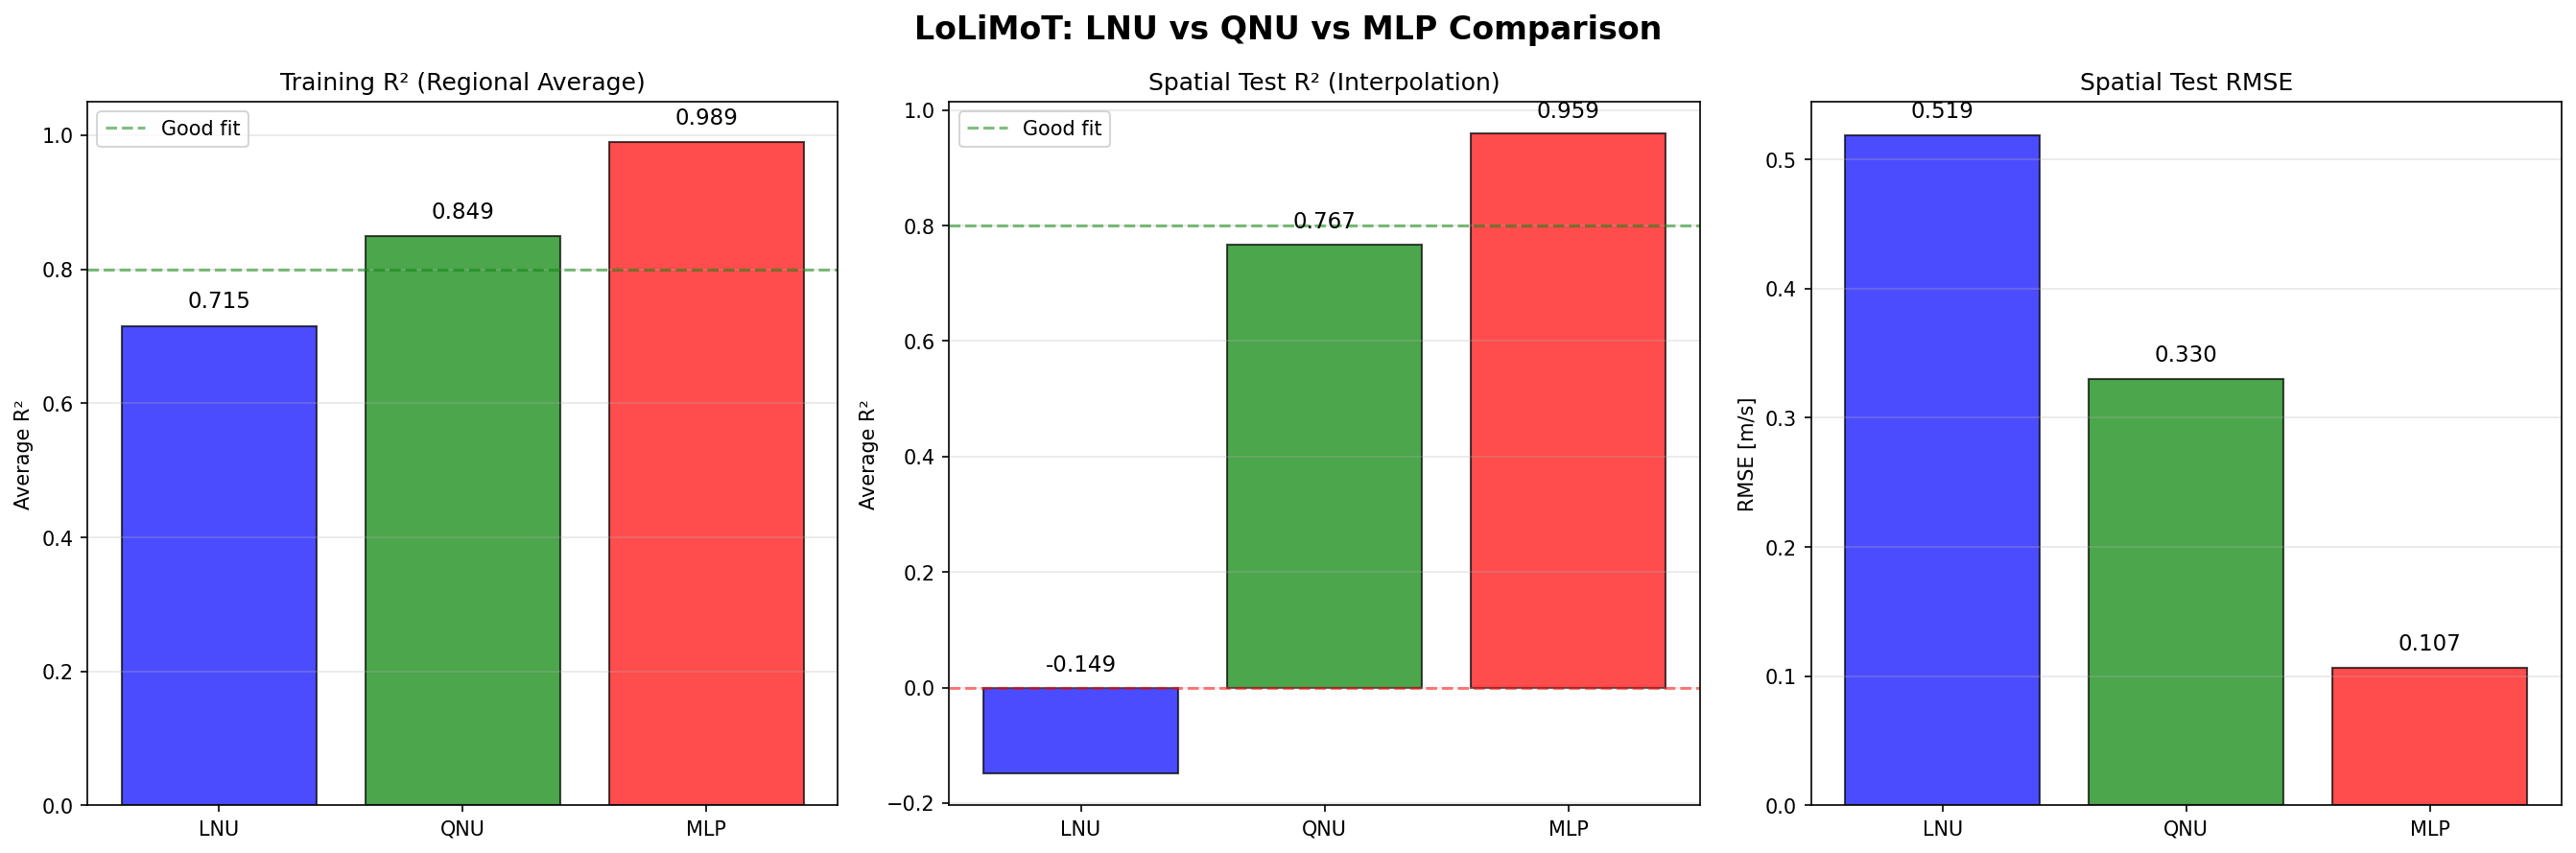

✓ Saved: step5_model_comparison.png


In [105]:
# ============================================================================
# VISUALIZATION 1: COMPARISON BAR CHART
# ============================================================================

print(f"\n{'='*80}")
print("CREATING VISUALIZATIONS")
print("="*80)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Prepare data
model_names = model_types_to_train
colors = {'LNU': 'blue', 'QNU': 'green', 'MLP': 'red'}

# Training R²
ax = axes[0]
train_R2_vals = [np.mean([all_region_metrics[mt][r]['R2'] for r in all_region_metrics[mt]]) 
                 for mt in model_names]
bars = ax.bar(model_names, train_R2_vals, color=[colors[mt] for mt in model_names], alpha=0.7, edgecolor='black')
ax.set_ylabel('Average R²')
ax.set_title('Training R² (Regional Average)')
ax.set_ylim([0, 1.05])
ax.axhline(0.8, color='green', linestyle='--', alpha=0.5, label='Good fit')
for bar, val in zip(bars, train_R2_vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, f'{val:.3f}', 
            ha='center', va='bottom', fontsize=11)
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

# Test R²
ax = axes[1]
test_R2_vals = [overall_metrics[mt]['R2'] for mt in model_names]
bars = ax.bar(model_names, test_R2_vals, color=[colors[mt] for mt in model_names], alpha=0.7, edgecolor='black')
ax.set_ylabel('Average R²')
ax.set_title('Spatial Test R² (Interpolation)')
ax.axhline(0, color='red', linestyle='--', alpha=0.5)
ax.axhline(0.8, color='green', linestyle='--', alpha=0.5, label='Good fit')
for bar, val in zip(bars, test_R2_vals):
    ax.text(bar.get_x() + bar.get_width()/2, max(bar.get_height(), 0) + 0.02, f'{val:.3f}', 
            ha='center', va='bottom', fontsize=11)
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

# Test RMSE
ax = axes[2]
test_RMSE_vals = [overall_metrics[mt]['RMSE'] for mt in model_names]
bars = ax.bar(model_names, test_RMSE_vals, color=[colors[mt] for mt in model_names], alpha=0.7, edgecolor='black')
ax.set_ylabel('RMSE [m/s]')
ax.set_title('Spatial Test RMSE')
for bar, val in zip(bars, test_RMSE_vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{val:.3f}', 
            ha='center', va='bottom', fontsize=11)
ax.grid(True, alpha=0.3, axis='y')

plt.suptitle('LoLiMoT: LNU vs QNU vs MLP Comparison', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'step5_model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step5_model_comparison.png")
plt.close()

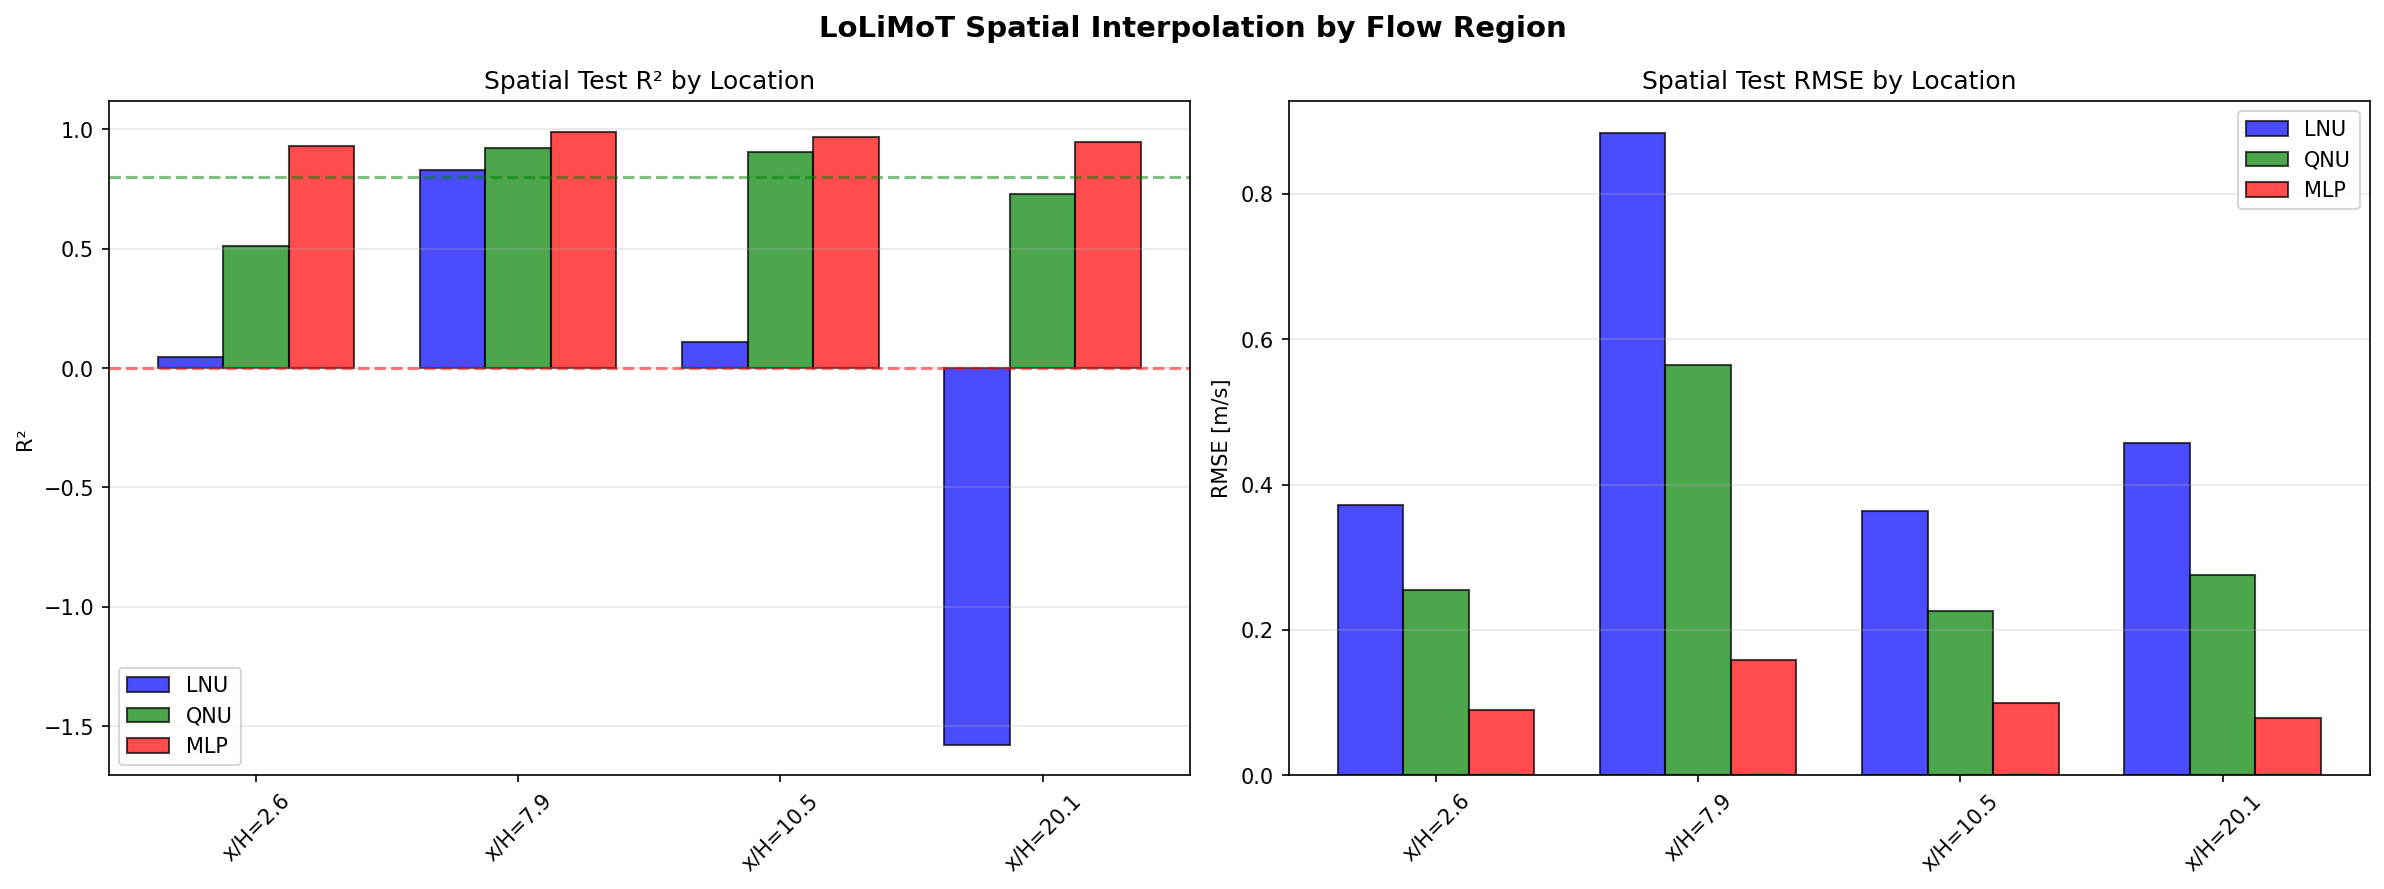

✓ Saved: step5_spatial_by_location.png


In [106]:
# ============================================================================
# VISUALIZATION 2: SPATIAL TEST BY LOCATION
# ============================================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

x_positions = np.arange(len(x_test))
width = 0.25

# R² by location
ax = axes[0]
for i, model_type in enumerate(model_names):
    R2_by_loc = []
    for x_loc in x_test:
        results_at_x = [r for r in spatial_results[model_type] if r['x'] == x_loc]
        R2_by_loc.append(np.mean([r['R2'] for r in results_at_x]))
    ax.bar(x_positions + i*width, R2_by_loc, width, label=model_type, 
           color=colors[model_type], alpha=0.7, edgecolor='black')

ax.set_xticks(x_positions + width)
ax.set_xticklabels([f'x/H={x/H_CUBE:.1f}' for x in x_test], rotation=45)
ax.set_ylabel('R²')
ax.set_title('Spatial Test R² by Location')
ax.axhline(0, color='red', linestyle='--', alpha=0.5)
ax.axhline(0.8, color='green', linestyle='--', alpha=0.5)
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

# RMSE by location
ax = axes[1]
for i, model_type in enumerate(model_names):
    RMSE_by_loc = []
    for x_loc in x_test:
        results_at_x = [r for r in spatial_results[model_type] if r['x'] == x_loc]
        RMSE_by_loc.append(np.mean([r['RMSE'] for r in results_at_x]))
    ax.bar(x_positions + i*width, RMSE_by_loc, width, label=model_type,
           color=colors[model_type], alpha=0.7, edgecolor='black')

ax.set_xticks(x_positions + width)
ax.set_xticklabels([f'x/H={x/H_CUBE:.1f}' for x in x_test], rotation=45)
ax.set_ylabel('RMSE [m/s]')
ax.set_title('Spatial Test RMSE by Location')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

plt.suptitle('LoLiMoT Spatial Interpolation by Flow Region', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'step5_spatial_by_location.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step5_spatial_by_location.png")
plt.close()

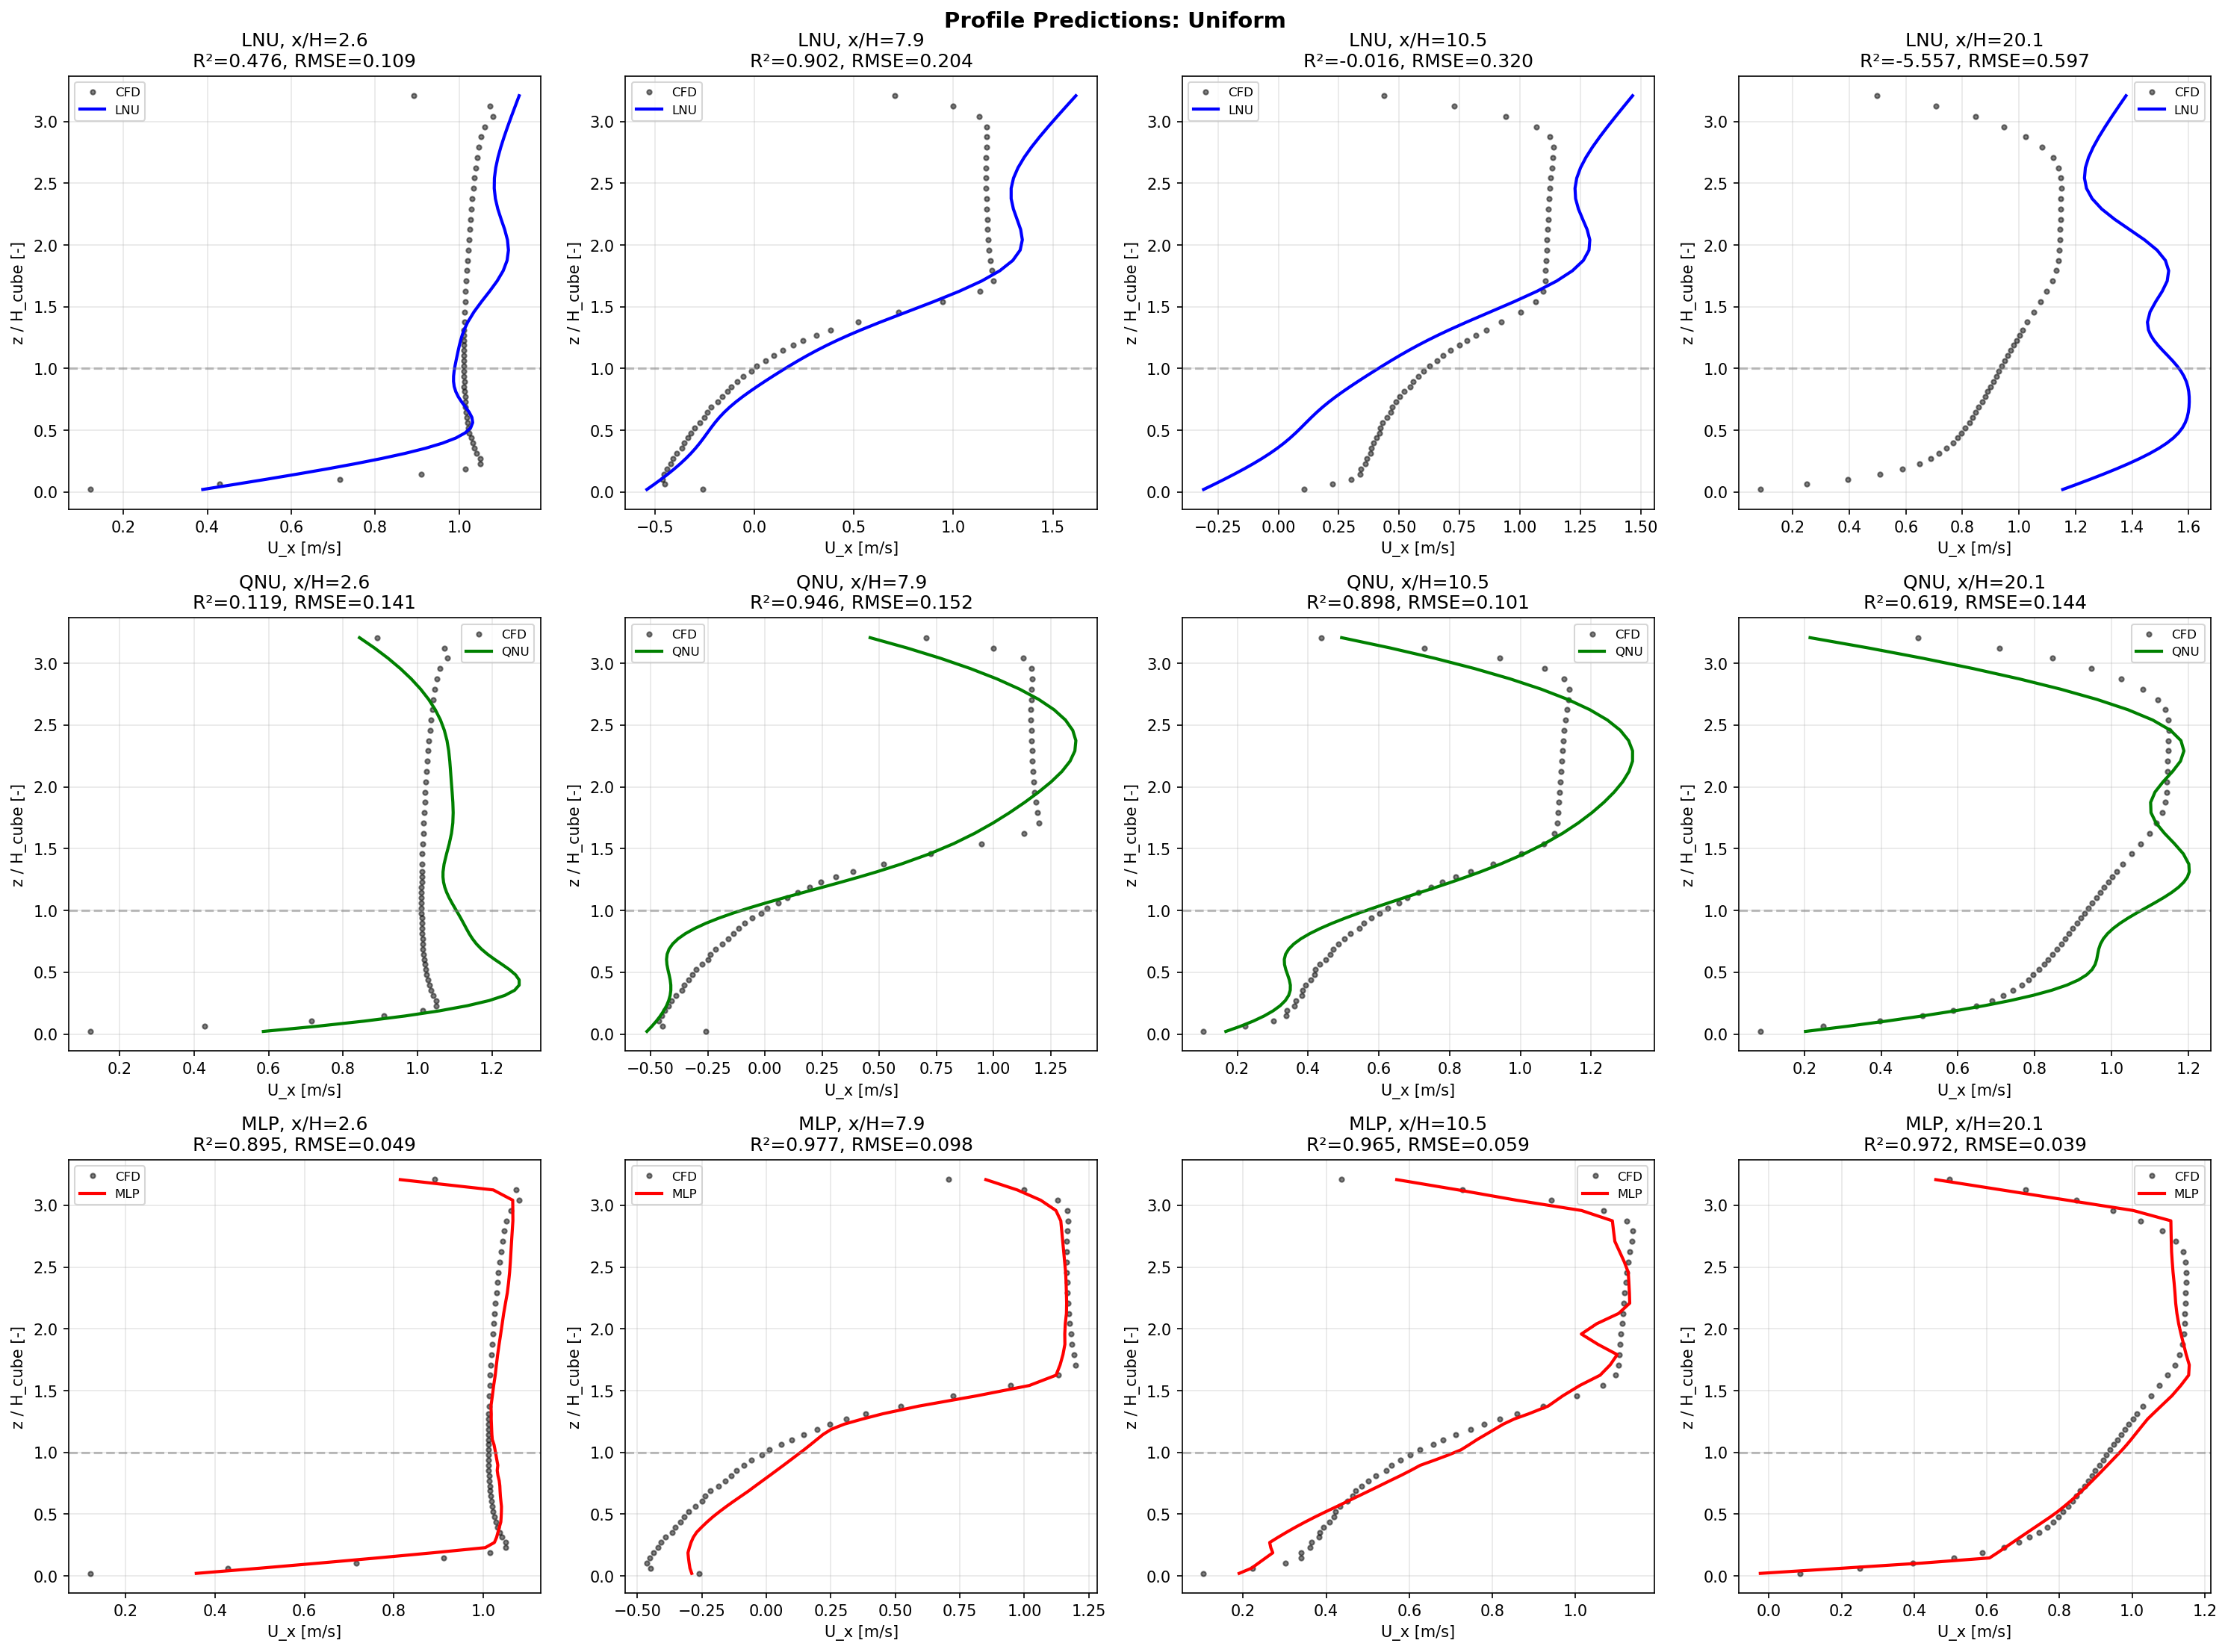

✓ Saved: step5_profile_comparison.png


In [107]:
# ============================================================================
# VISUALIZATION 3: PROFILE PREDICTIONS COMPARISON
# ============================================================================

# Select one test case for detailed comparison
test_case_id = list(all_cases_data.keys())[0]
test_case = all_cases_data[test_case_id]
test_params = case_parameters[test_case_id]

fig, axes = plt.subplots(len(model_names), len(x_test), figsize=(5*len(x_test), 5*len(model_names)))

for row, model_type in enumerate(model_names):
    region_models = all_region_models[model_type]
    
    for col, x_loc in enumerate(x_test):
        ax = axes[row, col] if len(model_names) > 1 else axes[col]
        
        if x_loc in test_case['profiles']:
            profile = test_case['profiles'][x_loc]
            z_cfd = profile['z']
            U_cfd = profile['U_x']
            
            # Predict
            U_pred = []
            for z_val in z_cfd:
                pred, _ = lolimot_predict(
                    x=x_loc, z=z_val,
                    U_ref=test_params['U_ref'], profile_type=test_params['profile_type'],
                    model_type=model_type,
                    region_models=region_models, regions=REGIONS,
                    feature_scaler=feature_scaler, onehot_encoder=onehot_encoder,
                    H_CUBE=H_CUBE
                )
                U_pred.append(pred)
            
            # Plot
            ax.plot(U_cfd, z_cfd/H_CUBE, 'ko', markersize=3, alpha=0.5, label='CFD')
            ax.plot(U_pred, z_cfd/H_CUBE, '-', color=colors[model_type], linewidth=2, label=model_type)
            
            # Metrics
            R2 = r2_score(U_cfd, U_pred)
            RMSE = np.sqrt(mean_squared_error(U_cfd, U_pred))
            
            ax.axhline(1.0, color='gray', linestyle='--', alpha=0.5)
            ax.set_xlabel('U_x [m/s]')
            ax.set_ylabel('z / H_cube [-]')
            ax.set_title(f'{model_type}, x/H={x_loc/H_CUBE:.1f}\nR²={R2:.3f}, RMSE={RMSE:.3f}')
            ax.legend(loc='best', fontsize=8)
            ax.grid(True, alpha=0.3)

plt.suptitle(f'Profile Predictions: {test_case["profile_name"]}', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'step5_profile_comparison.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step5_profile_comparison.png")
plt.close()


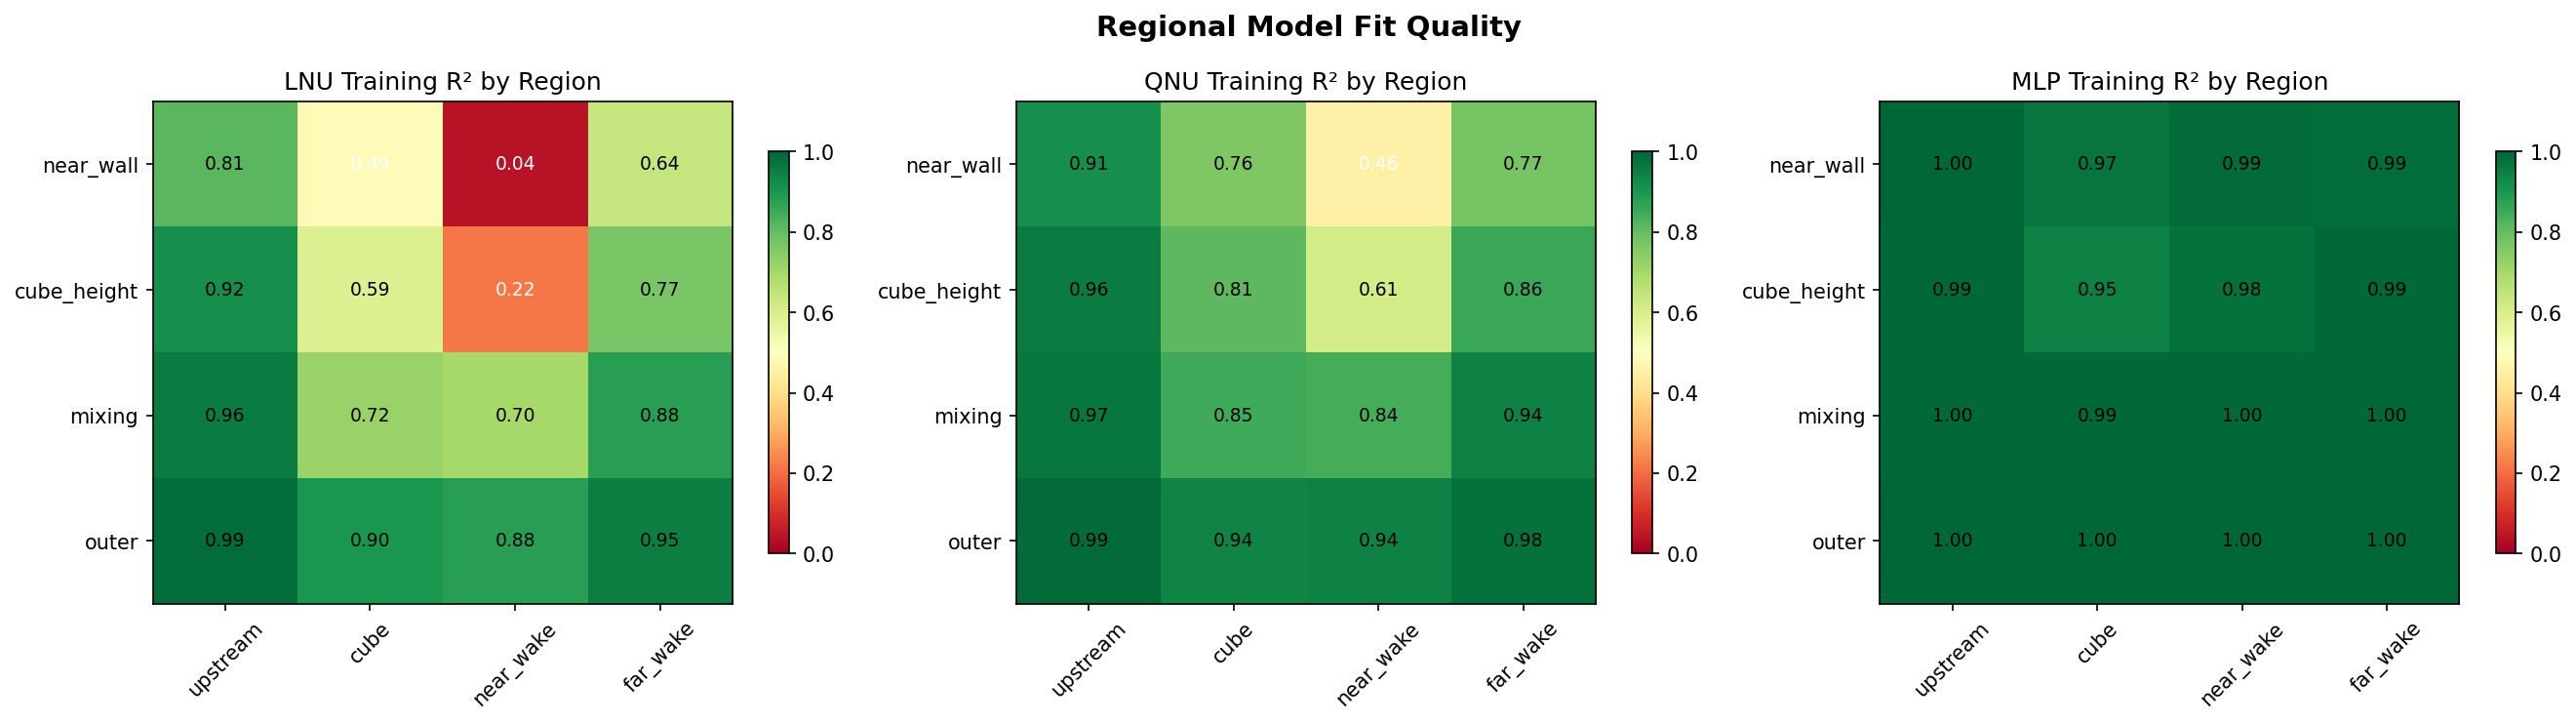

✓ Saved: step5_regional_R2_heatmap.png


In [108]:
# ============================================================================
# VISUALIZATION 4: REGIONAL R² HEATMAPS
# ============================================================================

fig, axes = plt.subplots(1, len(model_names), figsize=(6*len(model_names), 5))

x_names = list(X_REGIONS.keys())
z_names = list(Z_REGIONS.keys())

for ax, model_type in zip(axes if len(model_names) > 1 else [axes], model_names):
    R2_matrix = np.zeros((len(z_names), len(x_names)))
    
    for region_key in all_region_metrics[model_type]:
        region = REGIONS[region_key]
        i = z_names.index(region['z_name'])
        j = x_names.index(region['x_name'])
        R2_matrix[i, j] = all_region_metrics[model_type][region_key]['R2']
    
    im = ax.imshow(R2_matrix, cmap='RdYlGn', vmin=0, vmax=1, aspect='auto')
    ax.set_xticks(range(len(x_names)))
    ax.set_xticklabels(x_names, rotation=45)
    ax.set_yticks(range(len(z_names)))
    ax.set_yticklabels(z_names)
    ax.set_title(f'{model_type} Training R² by Region')
    plt.colorbar(im, ax=ax, shrink=0.8)
    
    # Add text
    for i in range(len(z_names)):
        for j in range(len(x_names)):
            color = 'white' if R2_matrix[i,j] < 0.5 else 'black'
            ax.text(j, i, f'{R2_matrix[i,j]:.2f}', ha='center', va='center', color=color, fontsize=9)

plt.suptitle('Regional Model Fit Quality', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'step5_regional_R2_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step5_regional_R2_heatmap.png")
plt.close()


INTERPRETABILITY ANALYSIS

Extracting LNU coefficients for physics interpretation...
Features: ['x_norm', 'z_norm', 'U_ref', 'type_Uniform', 'type_ABL+const', 'type_ABL+free', 'type_ABL+lam']

────────────────────────────────────────────────────────────────────────────────
LNU COEFFICIENTS BY REGION:
────────────────────────────────────────────────────────────────────────────────

Region                     β(x_norm)  β(z_norm)   β(U_ref)  Intercept       R²
--------------------------------------------------------------------------------
upstream_near_wall            -1.667      1.864      1.526      2.102    0.815
upstream_cube_height          -1.179      0.508      1.792      1.407    0.917
upstream_mixing               -0.413      0.325      1.963      2.379    0.957
upstream_outer                 0.100      0.067      2.059      3.142    0.986
cube_near_wall                -6.157      1.718      0.272     -2.711    0.488
cube_cube_height              -6.752      1.268      0.695  

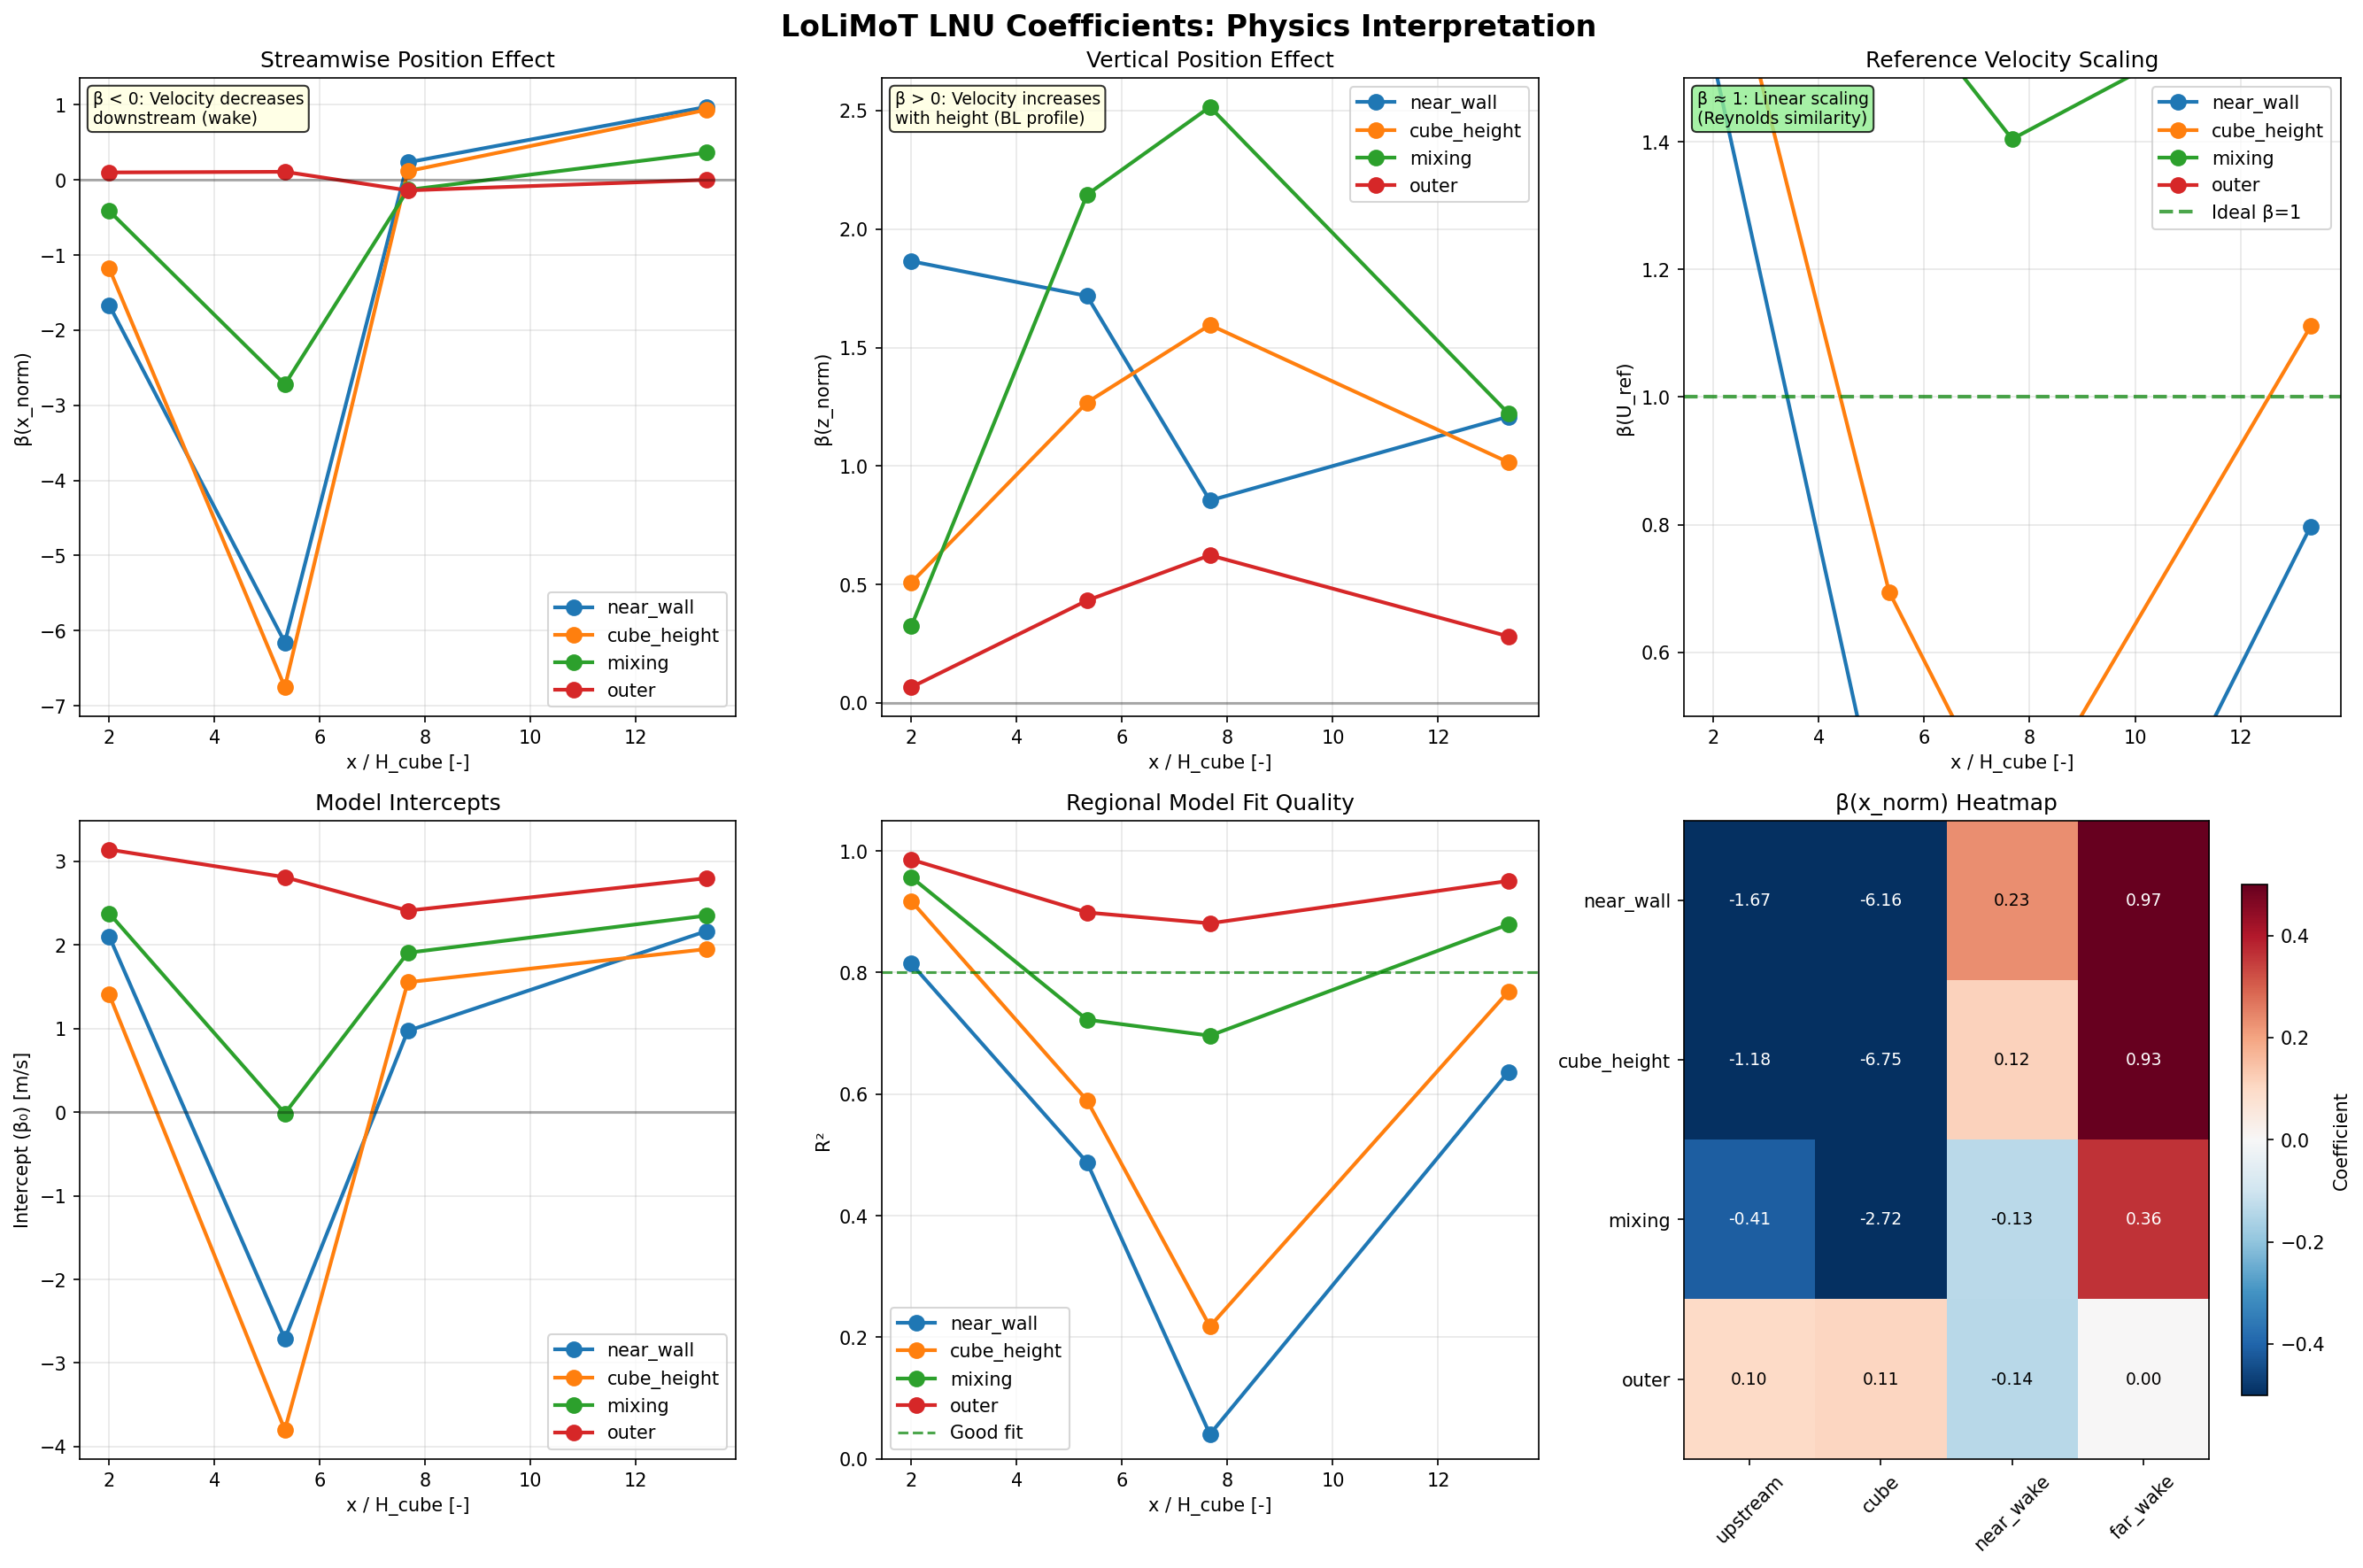


✓ Saved: step3c_5_interpretability.png
✓ Saved: step3c_lnu_coefficients.csv

────────────────────────────────────────────────────────────────────────────────
INTERPRETABILITY COMPARISON:
────────────────────────────────────────────────────────────────────────────────

    LOCAL MODELS (Step 3):
      • 165 separate models (one per z-height)
      • Coefficients vary continuously with z
      • Fine-grained z-resolution
      • No x-variation within model
    
    LoLiMoT (Step 3C):
      • 16 regional models
      • Coefficients grouped by physics regions
      • Coarser but more meaningful grouping
      • BOTH x and z variation captured within each model
      
    KEY INSIGHT:
      • LoLiMoT coefficients show HOW physics changes across regions
      • β(x_norm) reveals streamwise development of wake
      • β(z_norm) reveals boundary layer structure
      • Regional grouping aligns with flow physics!
    


In [109]:
# ============================================================================
# INTERPRETABILITY ANALYSIS (LNU COEFFICIENTS)
# ============================================================================

print(f"\n{'='*80}")
print("INTERPRETABILITY ANALYSIS")
print("="*80)

if 'LNU' in model_types_to_train:
    print("\nExtracting LNU coefficients for physics interpretation...")
    print(f"Features: {FEATURE_NAMES}")
    
    # Extract coefficients from all LNU regional models
    coef_data = []
    for region_key, model in all_region_models['LNU'].items():
        region = REGIONS[region_key]
        metrics = all_region_metrics['LNU'][region_key]
        
        coef_dict = {
            'region': region_key,
            'x_name': region['x_name'],
            'z_name': region['z_name'],
            'x_center': region['x_center'] / H_CUBE,
            'z_center': region['z_center'] / H_CUBE,
            'intercept': model.intercept_,
            'R2': metrics['R2'],
            'RMSE': metrics['RMSE'],
            'n_points': metrics['n_points'],
        }
        
        # Add each coefficient
        for i, fname in enumerate(FEATURE_NAMES):
            coef_dict[f'coef_{fname}'] = model.coef_[i]
        
        coef_data.append(coef_dict)
    
    df_coef = pd.DataFrame(coef_data)
    
    # ========================================================================
    # COEFFICIENT TABLE BY REGION
    # ========================================================================
    
    print(f"\n{'─'*80}")
    print("LNU COEFFICIENTS BY REGION:")
    print(f"{'─'*80}")
    print(f"\n{'Region':<25s} {'β(x_norm)':>10s} {'β(z_norm)':>10s} {'β(U_ref)':>10s} {'Intercept':>10s} {'R²':>8s}")
    print("-" * 80)
    
    for _, row in df_coef.iterrows():
        print(f"{row['region']:<25s} {row['coef_x_norm']:>10.3f} {row['coef_z_norm']:>10.3f} "
              f"{row['coef_U_ref']:>10.3f} {row['intercept']:>10.3f} {row['R2']:>8.3f}")
    
    # ========================================================================
    # PHYSICS INTERPRETATION
    # ========================================================================
    
    print(f"\n{'─'*80}")
    print("PHYSICS INTERPRETATION:")
    print(f"{'─'*80}")
    
    # Analyze x_norm coefficient (streamwise effect)
    print(f"\n1. STREAMWISE POSITION EFFECT β(x_norm):")
    for x_name in X_REGIONS.keys():
        subset = df_coef[df_coef['x_name'] == x_name]
        mean_coef = subset['coef_x_norm'].mean()
        print(f"   {x_name:12s}: β = {mean_coef:+.3f}  → ", end='')
        if mean_coef < -0.05:
            print("Velocity decreases downstream (wake deficit)")
        elif mean_coef > 0.05:
            print("Velocity increases downstream (acceleration)")
        else:
            print("Weak streamwise dependence")
    
    # Analyze z_norm coefficient (vertical effect)
    print(f"\n2. VERTICAL POSITION EFFECT β(z_norm):")
    for z_name in Z_REGIONS.keys():
        subset = df_coef[df_coef['z_name'] == z_name]
        mean_coef = subset['coef_z_norm'].mean()
        print(f"   {z_name:12s}: β = {mean_coef:+.3f}  → ", end='')
        if mean_coef > 0.1:
            print("Velocity increases with height (boundary layer)")
        elif mean_coef < -0.1:
            print("Velocity decreases with height (unusual)")
        else:
            print("Weak vertical dependence")
    
    # Analyze U_ref coefficient (scaling)
    print(f"\n3. REFERENCE VELOCITY SCALING β(U_ref):")
    mean_U_ref = df_coef['coef_U_ref'].mean()
    std_U_ref = df_coef['coef_U_ref'].std()
    print(f"   Mean: β = {mean_U_ref:.3f} ± {std_U_ref:.3f}")
    if 0.8 < mean_U_ref < 1.2:
        print(f"   ✅ CORRECT: Near-linear scaling with U_ref (Reynolds similarity)")
    else:
        print(f"   ⚠️ Non-linear scaling detected")
    
    # Analyze profile type effects
    print(f"\n4. INLET PROFILE TYPE EFFECTS:")
    type_features = ['coef_type_Uniform', 'coef_type_ABL+const', 'coef_type_ABL+free', 'coef_type_ABL+lam']
    type_names = ['Uniform', 'ABL+const', 'ABL+free', 'ABL+lam']
    for feat, name in zip(type_features, type_names):
        if feat in df_coef.columns:
            mean_coef = df_coef[feat].mean()
            print(f"   {name:12s}: β = {mean_coef:+.3f}")
    print(f"   Note: One-hot encoded, effects are relative")
    
    # ========================================================================
    # VISUALIZATION 5: COEFFICIENT INTERPRETATION
    # ========================================================================
    
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    fig.suptitle('LoLiMoT LNU Coefficients: Physics Interpretation', fontsize=16, fontweight='bold')
    
    # Plot 1: x_norm coefficient by region
    ax = axes[0, 0]
    for z_name in Z_REGIONS.keys():
        subset = df_coef[df_coef['z_name'] == z_name].sort_values('x_center')
        ax.plot(subset['x_center'], subset['coef_x_norm'], 'o-', label=z_name, markersize=8, linewidth=2)
    ax.axhline(0, color='black', linestyle='-', alpha=0.3)
    ax.set_xlabel('x / H_cube [-]')
    ax.set_ylabel('β(x_norm)')
    ax.set_title('Streamwise Position Effect')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # Add interpretation
    ax.text(0.02, 0.98, 'β < 0: Velocity decreases\ndownstream (wake)',
            transform=ax.transAxes, fontsize=9, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))
    
    # Plot 2: z_norm coefficient by region
    ax = axes[0, 1]
    for z_name in Z_REGIONS.keys():
        subset = df_coef[df_coef['z_name'] == z_name].sort_values('x_center')
        ax.plot(subset['x_center'], subset['coef_z_norm'], 'o-', label=z_name, markersize=8, linewidth=2)
    ax.axhline(0, color='black', linestyle='-', alpha=0.3)
    ax.set_xlabel('x / H_cube [-]')
    ax.set_ylabel('β(z_norm)')
    ax.set_title('Vertical Position Effect')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    ax.text(0.02, 0.98, 'β > 0: Velocity increases\nwith height (BL profile)',
            transform=ax.transAxes, fontsize=9, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))
    
    # Plot 3: U_ref coefficient by region
    ax = axes[0, 2]
    for z_name in Z_REGIONS.keys():
        subset = df_coef[df_coef['z_name'] == z_name].sort_values('x_center')
        ax.plot(subset['x_center'], subset['coef_U_ref'], 'o-', label=z_name, markersize=8, linewidth=2)
    ax.axhline(1.0, color='green', linestyle='--', alpha=0.7, linewidth=2, label='Ideal β=1')
    ax.set_xlabel('x / H_cube [-]')
    ax.set_ylabel('β(U_ref)')
    ax.set_title('Reference Velocity Scaling')
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_ylim([0.5, 1.5])
    
    ax.text(0.02, 0.98, 'β ≈ 1: Linear scaling\n(Reynolds similarity)',
            transform=ax.transAxes, fontsize=9, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.8))
    
    # Plot 4: Intercept by region
    ax = axes[1, 0]
    for z_name in Z_REGIONS.keys():
        subset = df_coef[df_coef['z_name'] == z_name].sort_values('x_center')
        ax.plot(subset['x_center'], subset['intercept'], 'o-', label=z_name, markersize=8, linewidth=2)
    ax.axhline(0, color='black', linestyle='-', alpha=0.3)
    ax.set_xlabel('x / H_cube [-]')
    ax.set_ylabel('Intercept (β₀) [m/s]')
    ax.set_title('Model Intercepts')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # Plot 5: Regional R² 
    ax = axes[1, 1]
    for z_name in Z_REGIONS.keys():
        subset = df_coef[df_coef['z_name'] == z_name].sort_values('x_center')
        ax.plot(subset['x_center'], subset['R2'], 'o-', label=z_name, markersize=8, linewidth=2)
    ax.axhline(0.8, color='green', linestyle='--', alpha=0.7, label='Good fit')
    ax.set_xlabel('x / H_cube [-]')
    ax.set_ylabel('R²')
    ax.set_title('Regional Model Fit Quality')
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_ylim([0, 1.05])
    
    # Plot 6: Coefficient heatmap for x_norm
    ax = axes[1, 2]
    x_names = list(X_REGIONS.keys())
    z_names = list(Z_REGIONS.keys())
    coef_matrix = np.zeros((len(z_names), len(x_names)))
    
    for _, row in df_coef.iterrows():
        i = z_names.index(row['z_name'])
        j = x_names.index(row['x_name'])
        coef_matrix[i, j] = row['coef_x_norm']
    
    im = ax.imshow(coef_matrix, cmap='RdBu_r', aspect='auto', vmin=-0.5, vmax=0.5)
    ax.set_xticks(range(len(x_names)))
    ax.set_xticklabels(x_names, rotation=45)
    ax.set_yticks(range(len(z_names)))
    ax.set_yticklabels(z_names)
    ax.set_title('β(x_norm) Heatmap')
    plt.colorbar(im, ax=ax, shrink=0.8, label='Coefficient')
    
    for i in range(len(z_names)):
        for j in range(len(x_names)):
            color = 'white' if abs(coef_matrix[i,j]) > 0.25 else 'black'
            ax.text(j, i, f'{coef_matrix[i,j]:.2f}', ha='center', va='center', color=color, fontsize=9)
    
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'step3c_5_interpretability.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("\n✓ Saved: step3c_5_interpretability.png")
    plt.close()
    
    # ========================================================================
    # SAVE COEFFICIENT TABLE
    # ========================================================================
    
    df_coef.to_csv(REPORTS_DIR / 'step3c_lnu_coefficients.csv', index=False)
    print(f"✓ Saved: step3c_lnu_coefficients.csv")
    
    # ========================================================================
    # COMPARISON: LoLiMoT vs LOCAL MODELS INTERPRETABILITY
    # ========================================================================
    
    print(f"\n{'─'*80}")
    print("INTERPRETABILITY COMPARISON:")
    print(f"{'─'*80}")
    print(f"""
    LOCAL MODELS (Step 3):
      • 165 separate models (one per z-height)
      • Coefficients vary continuously with z
      • Fine-grained z-resolution
      • No x-variation within model
    
    LoLiMoT (Step 3C):
      • 16 regional models
      • Coefficients grouped by physics regions
      • Coarser but more meaningful grouping
      • BOTH x and z variation captured within each model
      
    KEY INSIGHT:
      • LoLiMoT coefficients show HOW physics changes across regions
      • β(x_norm) reveals streamwise development of wake
      • β(z_norm) reveals boundary layer structure
      • Regional grouping aligns with flow physics!
    """)

else:
    print("\n⚠️  LNU not trained, skipping interpretability analysis")
    print("    Set MODEL_TYPE = 'LNU' or 'ALL' to enable")


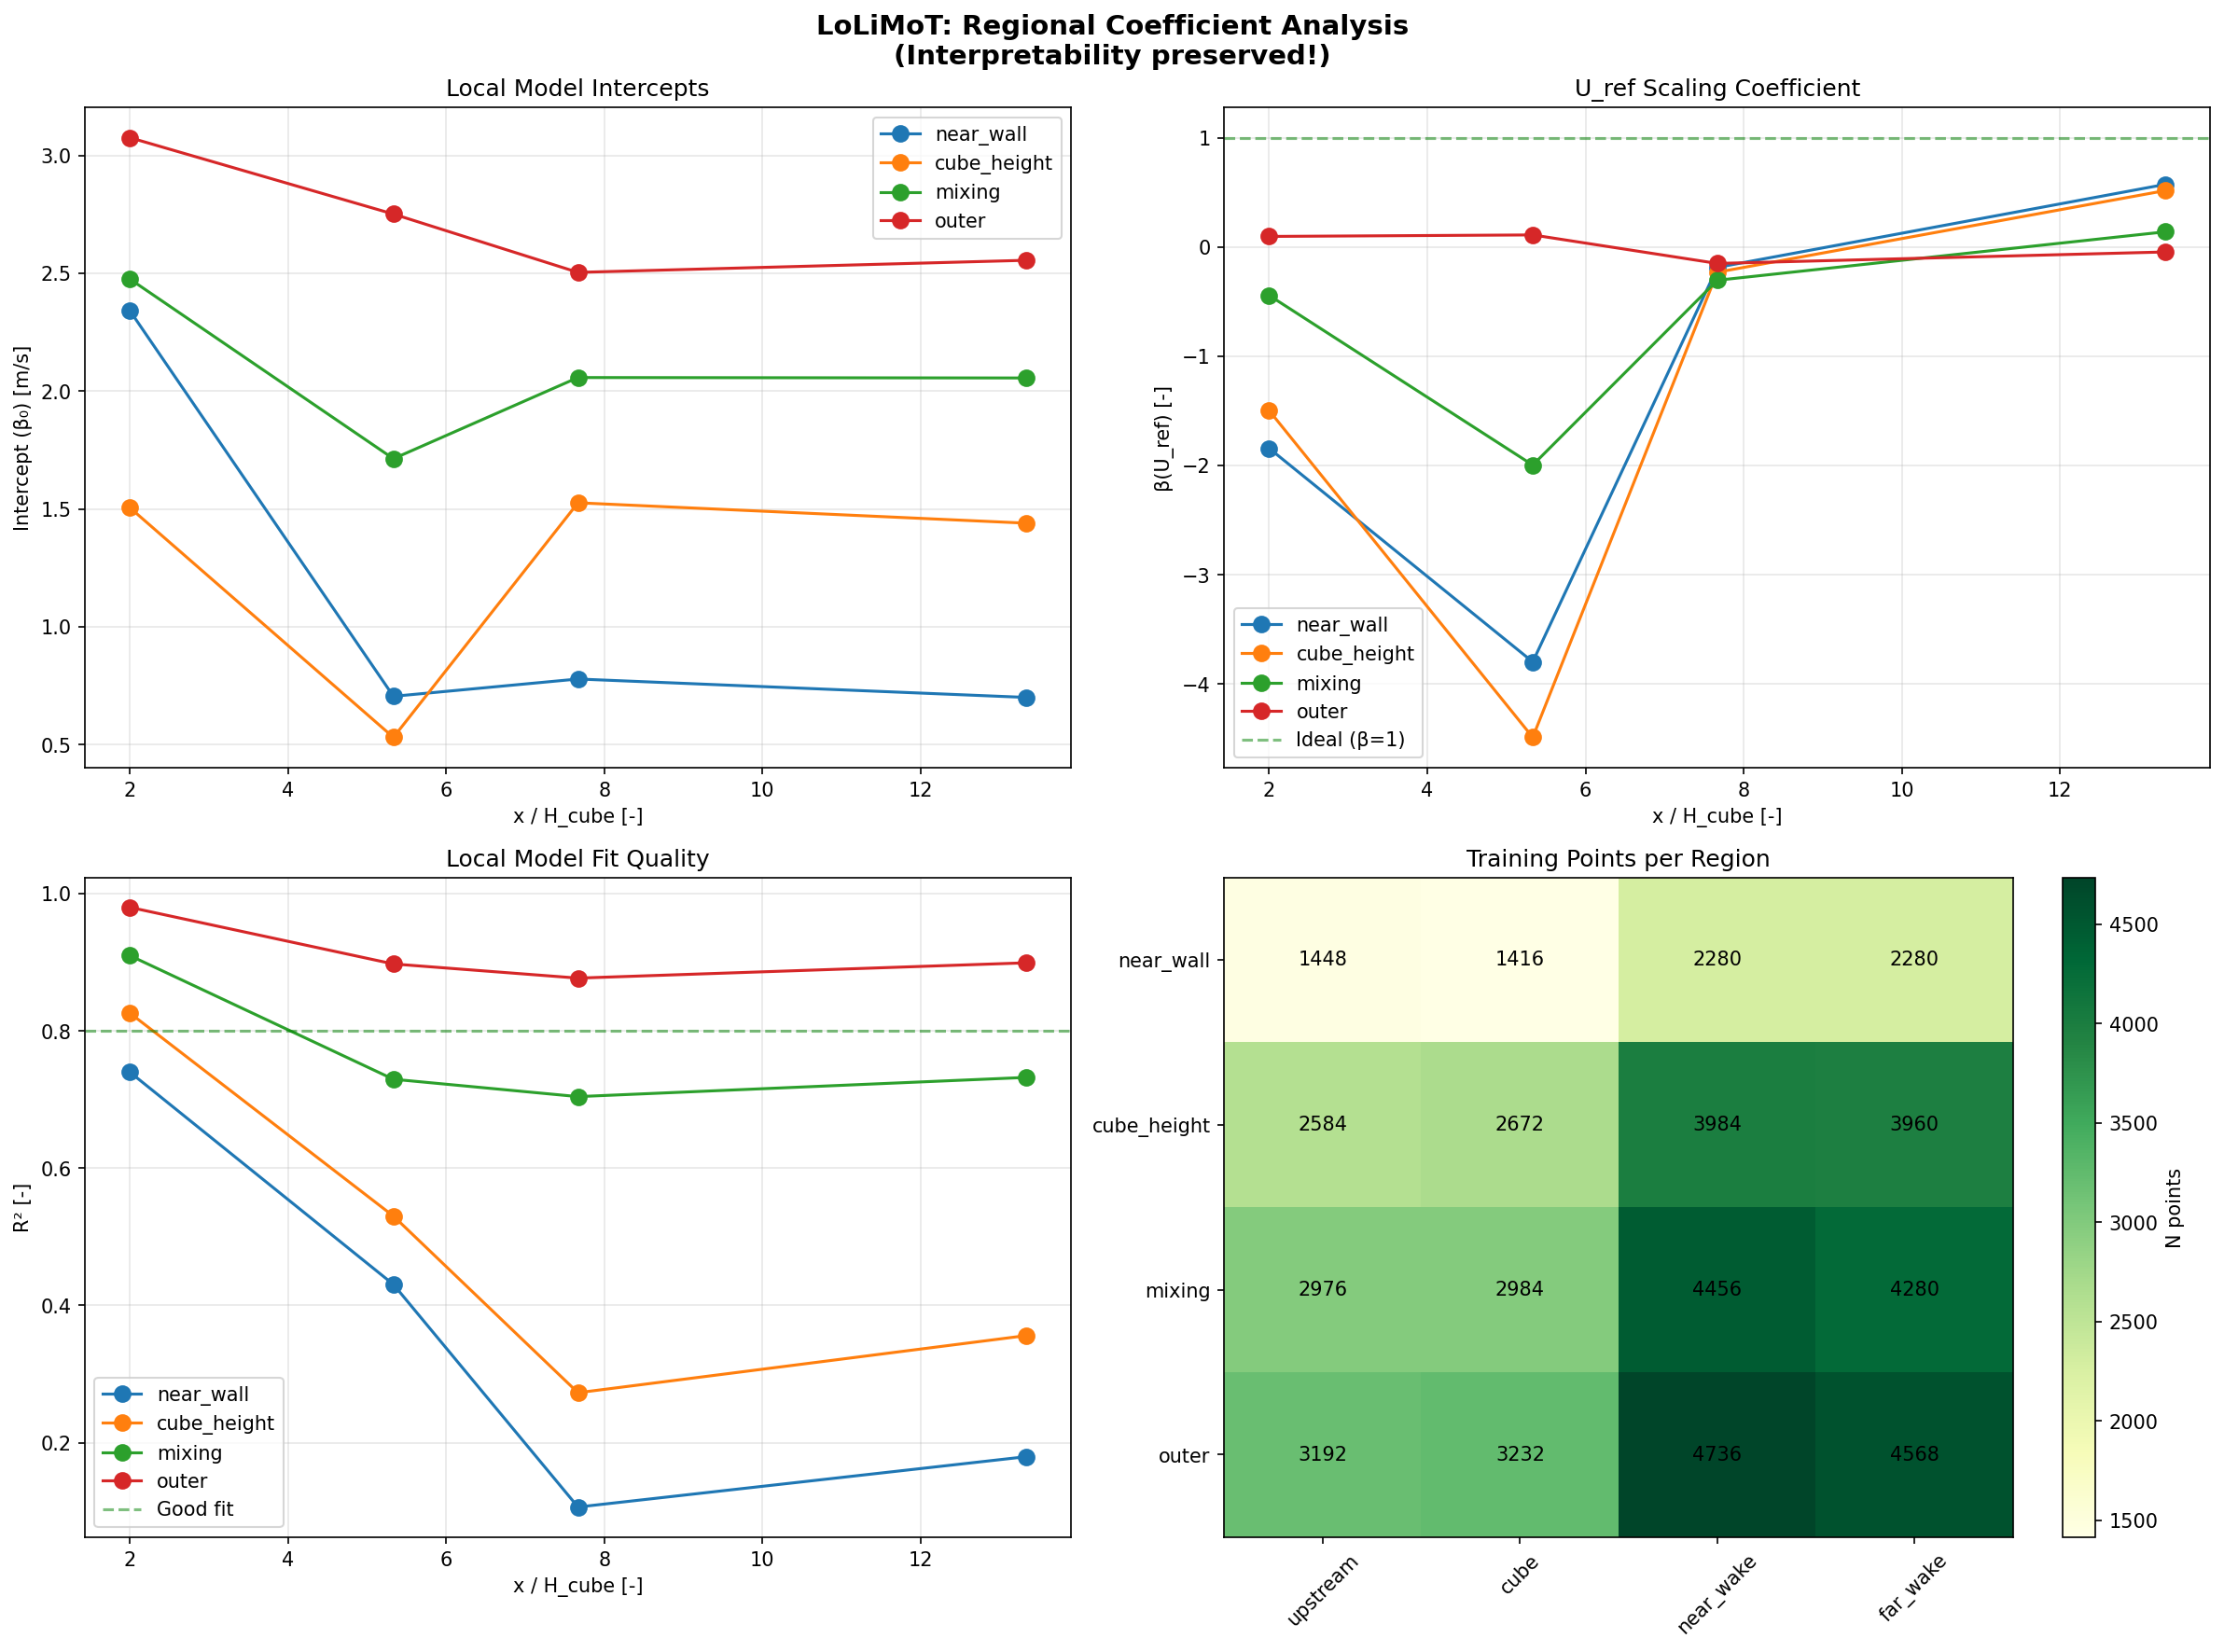

✓ Saved: step5_coefficient_analysis.png


In [110]:
# ============================================================================
# VISUALIZATION 5: COEFFICIENT INTERPRETATION
# ============================================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Extract coefficients by x-region and z-region
coef_data = []
for region_key, region in REGIONS.items():
    if region_key in region_metrics:
        m = region_metrics[region_key]
        coef_data.append({
            'region': region_key,
            'x_name': region['x_name'],
            'z_name': region['z_name'],
            'x_center': region['x_center'] / H_CUBE,
            'z_center': region['z_center'] / H_CUBE,
            'intercept': m['intercept'],
            'coef_U_ref': m['coef'][0],
            'R2': m['R2'],
            'n_points': m['n_points']
        })

df_coef = pd.DataFrame(coef_data)

# Plot 1: Intercept by region
ax = axes[0, 0]
for z_name in Z_REGIONS.keys():
    subset = df_coef[df_coef['z_name'] == z_name]
    ax.plot(subset['x_center'], subset['intercept'], 'o-', label=z_name, markersize=8)
ax.set_xlabel('x / H_cube [-]')
ax.set_ylabel('Intercept (β₀) [m/s]')
ax.set_title('Local Model Intercepts')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 2: U_ref coefficient by region
ax = axes[0, 1]
for z_name in Z_REGIONS.keys():
    subset = df_coef[df_coef['z_name'] == z_name]
    ax.plot(subset['x_center'], subset['coef_U_ref'], 'o-', label=z_name, markersize=8)
ax.axhline(1.0, color='green', linestyle='--', alpha=0.5, label='Ideal (β=1)')
ax.set_xlabel('x / H_cube [-]')
ax.set_ylabel('β(U_ref) [-]')
ax.set_title('U_ref Scaling Coefficient')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 3: R² by region
ax = axes[1, 0]
for z_name in Z_REGIONS.keys():
    subset = df_coef[df_coef['z_name'] == z_name]
    ax.plot(subset['x_center'], subset['R2'], 'o-', label=z_name, markersize=8)
ax.axhline(0.8, color='green', linestyle='--', alpha=0.5, label='Good fit')
ax.set_xlabel('x / H_cube [-]')
ax.set_ylabel('R² [-]')
ax.set_title('Local Model Fit Quality')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 4: Points per region
ax = axes[1, 1]
x_names = list(X_REGIONS.keys())
z_names = list(Z_REGIONS.keys())
points_matrix = np.zeros((len(z_names), len(x_names)))

for _, row in df_coef.iterrows():
    i = z_names.index(row['z_name'])
    j = x_names.index(row['x_name'])
    points_matrix[i, j] = row['n_points']

im = ax.imshow(points_matrix, cmap='YlGn', aspect='auto')
ax.set_xticks(range(len(x_names)))
ax.set_xticklabels(x_names, rotation=45)
ax.set_yticks(range(len(z_names)))
ax.set_yticklabels(z_names)
ax.set_title('Training Points per Region')
plt.colorbar(im, ax=ax, label='N points')

# Add text
for i in range(len(z_names)):
    for j in range(len(x_names)):
        ax.text(j, i, f'{int(points_matrix[i,j])}', ha='center', va='center')

plt.suptitle('LoLiMoT: Regional Coefficient Analysis\n'
             '(Interpretability preserved!)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'step5_coefficient_analysis.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step5_coefficient_analysis.png")
plt.close()

In [111]:
# ============================================================================
# SAVE RESULTS
# ============================================================================

print(f"\n{'='*80}")
print("SAVING RESULTS")
print("="*80)

results = {
    'all_region_models': all_region_models,
    'all_region_metrics': all_region_metrics,
    'regions': REGIONS,
    'X_REGIONS': X_REGIONS,
    'Z_REGIONS': Z_REGIONS,
    'feature_scaler': feature_scaler,
    'onehot_encoder': onehot_encoder,
    'x_train': x_train,
    'x_test': x_test,
    'spatial_results': spatial_results,
    'overall_metrics': overall_metrics,
    'H_CUBE': H_CUBE,
    'FEATURE_NAMES': FEATURE_NAMES,
    'model_types': model_types_to_train,
}

if 'QNU' in model_types_to_train:
    results['poly_transformer'] = poly_transformer

with open(RESULTS_OUTPUT, 'wb') as f:
    pickle.dump(results, f)

print(f"✓ Saved: {RESULTS_OUTPUT}")


SAVING RESULTS
✓ Saved: /home/vita/ML/DACI/Multi_Case_CFD/results/reports/step5_lolimot_results.pkl


In [112]:
# ============================================================================
# FINAL SUMMARY
# ============================================================================

print(f"\n{'='*80}")
print("STEP 3C COMPLETE - LoLiMoT COMPARISON SUMMARY")
print("="*80)

print(f"""
🎯 LoLiMoT WITH LNU/QNU/MLP COMPARISON:

CONFIGURATION:
  • {len(X_REGIONS)} x-regions × {len(Z_REGIONS)} z-regions = {N_REGIONS} total regions
  • Features: {FEATURE_NAMES}
  • Training: {len(x_train)} x-locations, Testing: {len(x_test)} x-locations

MODEL COMPARISON:
""")

print(f"  {'Model':<8s} {'Train R²':>10s} {'Test R²':>10s} {'Test RMSE':>12s} {'Params':>10s}")
print(f"  {'-'*55}")

for model_type in model_types_to_train:
    train_R2 = np.mean([all_region_metrics[model_type][r]['R2'] 
                        for r in all_region_metrics[model_type]])
    test_R2 = overall_metrics[model_type]['R2']
    test_RMSE = overall_metrics[model_type]['RMSE']
    total_params = sum([all_region_metrics[model_type][r]['n_params'] 
                        for r in all_region_metrics[model_type]])
    print(f"  {model_type:<8s} {train_R2:>10.3f} {test_R2:>10.3f} {test_RMSE:>12.4f} {total_params:>10d}")

print(f"""
FILES CREATED:
  ✓ step3c_1_model_comparison.png
  ✓ step3c_2_spatial_by_location.png
  ✓ step3c_3_profile_comparison.png
  ✓ step3c_4_regional_R2_heatmap.png
  ✓ step3c_lolimot_results.pkl
""")

print("="*80)
print("✓ LoLiMoT COMPARISON COMPLETE")
print("="*80)


STEP 3C COMPLETE - LoLiMoT COMPARISON SUMMARY

🎯 LoLiMoT WITH LNU/QNU/MLP COMPARISON:

CONFIGURATION:
  • 4 x-regions × 4 z-regions = 16 total regions
  • Features: ['x_norm', 'z_norm', 'U_ref', 'type_Uniform', 'type_ABL+const', 'type_ABL+free', 'type_ABL+lam']
  • Training: 21 x-locations, Testing: 4 x-locations

MODEL COMPARISON:

  Model      Train R²    Test R²    Test RMSE     Params
  -------------------------------------------------------
  LNU           0.715     -0.149       0.5188        128
  QNU           0.849      0.767       0.3304        576
  MLP           0.989      0.959       0.1067       6096

FILES CREATED:
  ✓ step3c_1_model_comparison.png
  ✓ step3c_2_spatial_by_location.png
  ✓ step3c_3_profile_comparison.png
  ✓ step3c_4_regional_R2_heatmap.png
  ✓ step3c_lolimot_results.pkl

✓ LoLiMoT COMPARISON COMPLETE
